In [3]:
# Upload file from local computer
from google.colab import files
uploaded = files.upload()

# Import pandas
import pandas as pd

# Load the uploaded file
df = pd.read_csv("big_data.csv")

# Show first 5 rows
df.head()

Saving big_data.csv to big_data.csv


,Authors,Author full names,Author(s) ID,Title,Year,Source title,Volume,Issue,Art. No.,Page start,...,ISBN,CODEN,PubMed ID,Language of Original Document,Abbreviated Source Title,Document Type,Publication Stage,Open Access,Source,EID
0,Ajaegbo N.G.; Prasad R.; Abdullahi H.I.; Awoke O.,"Ajaegbo, Nkechi Gloria (60730247700); Prasad, ...",60730247700; 57191422092; 60730231800; 5971624...,A Computational Framework for Inclusive Assess...,2026,Student Enrollment and Retention Strategies to...,NaN,NaN,NaN,95,...,979-833737948-7; 979-833737946-3; 979-833737947-0,NaN,NaN,English,Student Enrollment and Retention Strategies to...,Book chapter,Final,NaN,Scopus,2-s2.0-105044124063
1,Hong Y.Z.; Rani M.N.A.; Radzuan N.F.M.; Yen L....,"Hong, Yam Zheng (59522138000); Rani, Mohd Nors...",59522138000; 57280898600; 57280264100; 5952149...,AN EARLY WARNING SYSTEM FOR STUDENTS AT RISK U...,2024,Journal of Engineering Science and Technology,19,1,NaN,131,...,NaN,NaN,NaN,English,J. Eng. Sci. Technol.,Article,Final,NaN,Scopus,2-s2.0-85199341707
2,Ewais A.; Arram A.; Diab S.; Alkhazaleh H.A.; ...,"Ewais, Ahmed. (35179213000); Arram, Anas (5639...",35179213000; 56394464200; 57219508139; 5966242...,Using machine learning for early identificatio...,2026,Scientific Reports,16,1,19944,NaN,...,NaN,NaN,42031821.0,English,Sci. Rep.,Article,Final,All Open Access; Gold Open Access,Scopus,2-s2.0-105043648818
3,Gu W.; Yang F.; Li W.; Wang Z.; Zhu Z.,"Gu, Wenyuan (60207267700); Yang, Fanfan (60503...",60207267700; 60503003900; 60503792000; 6017738...,Intelligent monitoring system for hazardous so...,2025,Experimental Technology and Management,42,12,NaN,238,...,NaN,NaN,NaN,Chinese,Exp. Tech. Manag.,Article,Final,NaN,Scopus,2-s2.0-105032794504
4,Dhanalakshmi B.; Chakresh N.K.; Indhuja V.,"Dhanalakshmi, B. (57282085000); Chakresh, N.K....",57282085000; 60607270700; 58069227800,A Data-Driven Software Framework to Predict an...,2025,ICRTEECT 2025 - 2nd International Conference o...,NaN,NaN,NaN,NaN,...,979-833158172-5,NaN,NaN,English,"ICRTEECT - Int. Conf. Recent Trends Electr., E...",Conference paper,Final,NaN,Scopus,2-s2.0-105037326377


In [4]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 252 entries, 0 to 251
Data columns (total 35 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Authors                        251 non-null    object 
 1   Author full names              251 non-null    object 
 2   Author(s) ID                   251 non-null    object 
 3   Title                          252 non-null    object 
 4   Year                           252 non-null    int64  
 5   Source title                   252 non-null    object 
 6   Volume                         154 non-null    object 
 7   Issue                          99 non-null     object 
 8   Art. No.                       72 non-null     object 
 9   Page start                     148 non-null    object 
 10  Page end                       148 non-null    object 
 11  Cited by                       252 non-null    int64  
 12  DOI                            228 non-null    obj

/tmp/ipykernel_469/3083119614.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Publication Count', y='Country', data=top_countries_df, palette='Spectral')


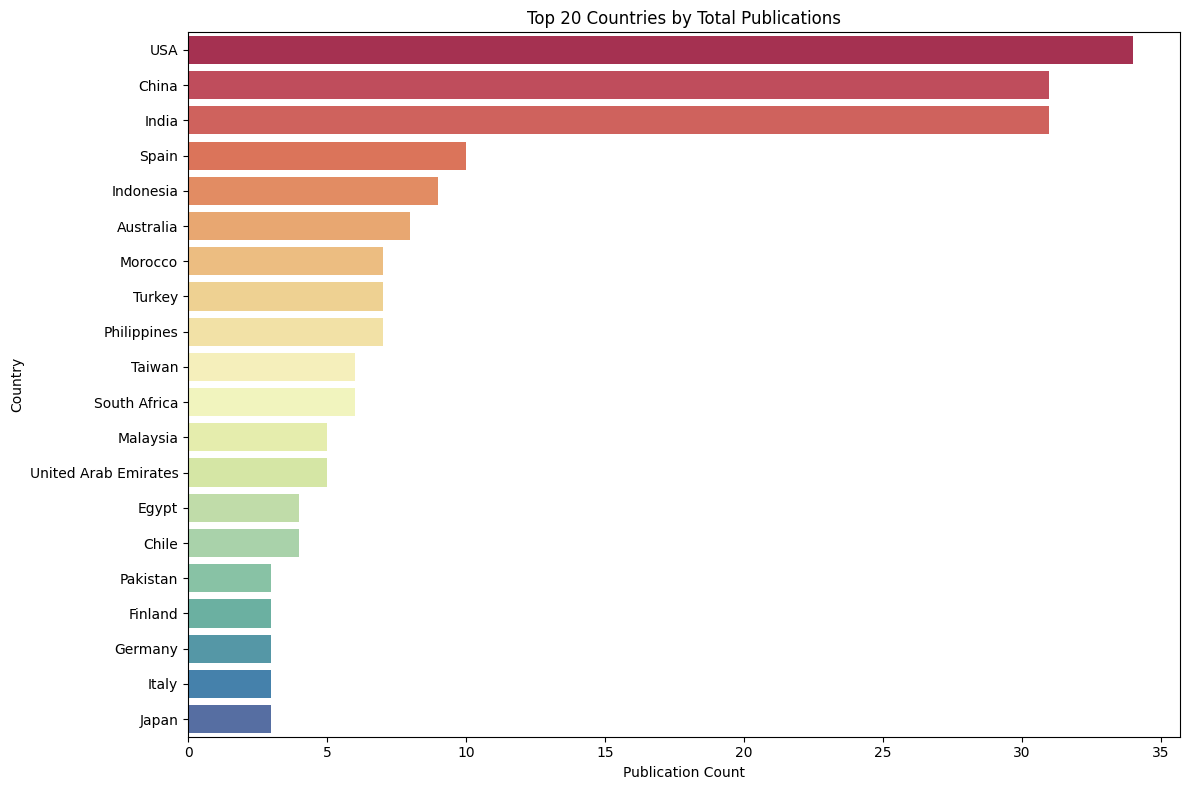

In [5]:
from collections import Counter
import re
import matplotlib.pyplot as plt
import seaborn as sns

# Drop rows where 'Affiliations' is NaN
affiliations_df = df.dropna(subset=['Affiliations']).copy()

all_countries = []
for affiliation_str in affiliations_df['Affiliations']:
    # Split by common delimiters (comma, semicolon) and take the last part
    # This often contains the country name
    parts = re.split(r'[,;]', affiliation_str)
    if parts:
        country = parts[-1].strip()
        # Further cleaning: remove text in parentheses, digits, and replace non-alphanumeric with spaces
        country = re.sub(r'\([^)]*\)', '', country) # Remove text in parentheses
        country = re.sub(r'\d+', '', country)       # Remove digits
        country = re.sub(r'[\W_]+', ' ', country)    # Replace non-alphanumeric with space
        country = country.strip().title() # Capitalize first letter of each word for consistency

        # Standardize common country name variations
        if 'Usa' in country:
            country = 'USA'
        elif 'United States' in country:
            country = 'USA'
        elif 'Uk' in country:
            country = 'UK'
        elif 'United Kingdom' in country:
            country = 'UK'
        elif 'Peoples R China' in country or 'Pr China' in country:
            country = 'China'
        elif 'Germany Federal Republic' in country:
            country = 'Germany'
        elif 'Korea South' in country:
            country = 'South Korea'

        # Add country to list if it's not empty, too short, or purely numeric
        if country and len(country) > 2 and not country.isdigit():
            all_countries.append(country)

# Count the frequency of each country
country_counts = Counter(all_countries)

# Get the top 20 countries
num_top_countries = 20
top_countries = country_counts.most_common(num_top_countries)

# Convert to DataFrame for easier plotting
top_countries_df = pd.DataFrame(top_countries, columns=['Country', 'Publication Count'])

# Plotting the top countries
plt.figure(figsize=(12, 8))
sns.barplot(x='Publication Count', y='Country', data=top_countries_df, palette='Spectral')
plt.title(f'Top {num_top_countries} Countries by Total Publications')
plt.xlabel('Publication Count')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

/tmp/ipykernel_469/1479586049.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Total Citations', y='Author', data=top_authors_citations_df, palette='viridis')


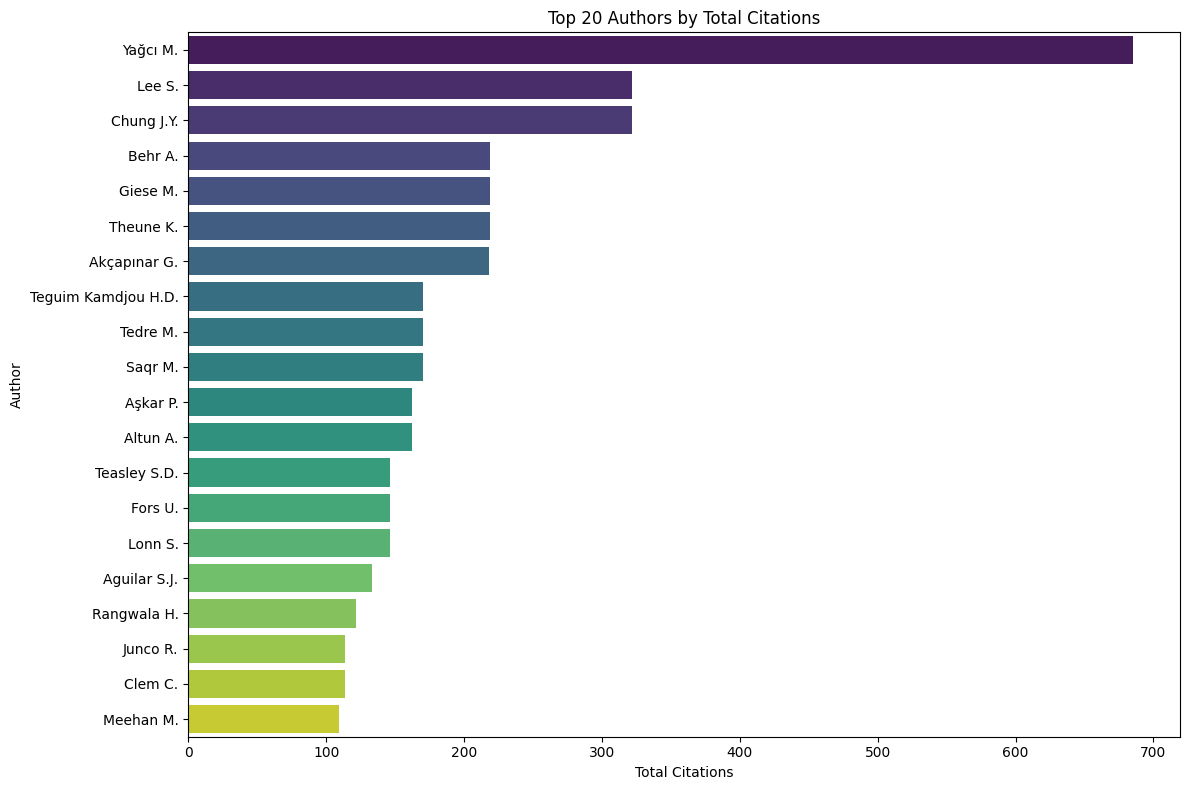

In [6]:
from collections import defaultdict
import matplotlib.pyplot as plt
import seaborn as sns

# Create a dictionary to store total citations per author
author_citations = defaultdict(float)

# Iterate through each row of the DataFrame
for index, row in df.iterrows():
    authors_str = row['Authors']
    cited_by = row['Cited by']

    if pd.isna(authors_str) or pd.isna(cited_by):
        continue

    # Split the authors string by semicolon
    authors = [author.strip() for author in authors_str.split(';') if author.strip()]

    # Add the 'Cited by' count to each author
    for author in authors:
        author_citations[author] += cited_by

# Convert the dictionary to a DataFrame
author_citations_df = pd.DataFrame(author_citations.items(), columns=['Author', 'Total Citations'])

# Sort by Total Citations in descending order
author_citations_df = author_citations_df.sort_values(by='Total Citations', ascending=False)

# Get the top 20 authors by total citations
num_top_authors_citations = 20
top_authors_citations_df = author_citations_df.head(num_top_authors_citations)

# Plotting the top authors by total citations
plt.figure(figsize=(12, 8))
sns.barplot(x='Total Citations', y='Author', data=top_authors_citations_df, palette='viridis')
plt.title(f'Top {num_top_authors_citations} Authors by Total Citations')
plt.xlabel('Total Citations')
plt.ylabel('Author')
plt.tight_layout()
plt.show()

In [7]:
print(df.isnull().sum())

Authors                            1
Author full names                  1
Author(s) ID                       1
Title                              0
Year                               0
Source title                       0
Volume                            98
Issue                            153
Art. No.                         180
Page start                       104
Page end                         104
Cited by                           0
DOI                               24
Link                               0
Affiliations                       3
Authors with affiliations          3
Abstract                           0
Author Keywords                   17
Index Keywords                    73
Funding Details                  166
Funding Texts                    167
Correspondence Address            76
Editors                          200
Publisher                          1
ISSN                              91
ISBN                             137
CODEN                            234
P

Now, let's preprocess some key columns:

1.  **'Cited by'**: Convert to numeric and fill missing values with 0 (assuming no citation means 0 citations).
2.  **'Year'**: Ensure it's a numeric type and fill any missing values with the median year.
3.  **'Open Access'**: Simplify this column into 'Open Access' (if any related string is present) or 'Not Open Access' (if NaN or otherwise).


In [8]:
# Convert 'Cited by' to numeric, filling NaNs with 0
df['Cited by'] = pd.to_numeric(df['Cited by'], errors='coerce').fillna(0)

# Convert 'Year' to numeric, filling NaNs with the median year
df['Year'] = pd.to_numeric(df['Year'], errors='coerce')
median_year = df['Year'].median()
df['Year'] = df['Year'].fillna(median_year).astype(int)

# Simplify 'Open Access' column
def classify_open_access(value):
    if pd.isna(value):
        return 'Not Open Access'
    elif 'Open Access' in value:
        return 'Open Access'
    else:
        return 'Not Open Access'

df['Open Access Simplified'] = df['Open Access'].apply(classify_open_access)

print("Preprocessing complete. Here's a look at the updated info and the new 'Open Access Simplified' column value counts:")
print(df[['Cited by', 'Year', 'Open Access Simplified']].info())
print("\nValue counts for 'Open Access Simplified':")
print(df['Open Access Simplified'].value_counts())

Preprocessing complete. Here's a look at the updated info and the new 'Open Access Simplified' column value counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 252 entries, 0 to 251
Data columns (total 3 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Cited by                252 non-null    int64 
 1   Year                    252 non-null    int64 
 2   Open Access Simplified  252 non-null    object
dtypes: int64(2), object(1)
memory usage: 6.0+ KB
None

Value counts for 'Open Access Simplified':
Open Access Simplified
Not Open Access    155
Open Access         97
Name: count, dtype: int64


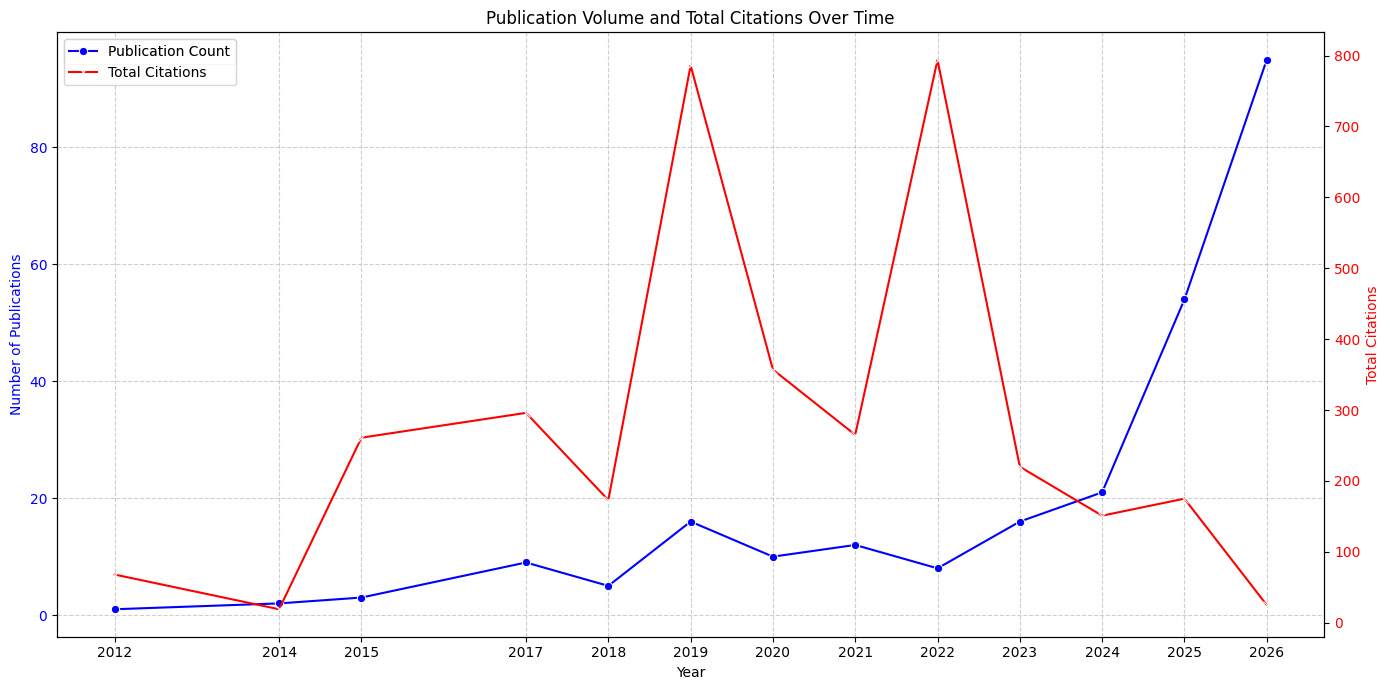

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Group by 'Year' to get publication count and total citations
year_trend = df.groupby('Year').agg(
    Publication_Count=('Title', 'count'),  # Count publications per year
    Total_Citations=('Cited by', 'sum')    # Sum citations per year
).reset_index()

# Create a figure with two subplots
fig, ax1 = plt.subplots(figsize=(14, 7))

# Plot Publication Count on the first y-axis (left)
sns.lineplot(x='Year', y='Publication_Count', data=year_trend, marker='o', ax=ax1, color='blue', label='Publication Count')
ax1.set_xlabel('Year')
ax1.set_ylabel('Number of Publications', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')
ax1.set_title('Publication Volume and Total Citations Over Time')
ax1.grid(True, linestyle='--', alpha=0.6)

# Create a second y-axis (right) for Total Citations
ax2 = ax1.twinx()
sns.lineplot(x='Year', y='Total_Citations', data=year_trend, marker='x', ax=ax2, color='red', label='Total Citations')
ax2.set_ylabel('Total Citations', color='red')
ax2.tick_params(axis='y', labelcolor='red')

# Add legends for both lines
lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc='upper left')

plt.xticks(year_trend['Year'], rotation=45)
plt.tight_layout()
plt.show()

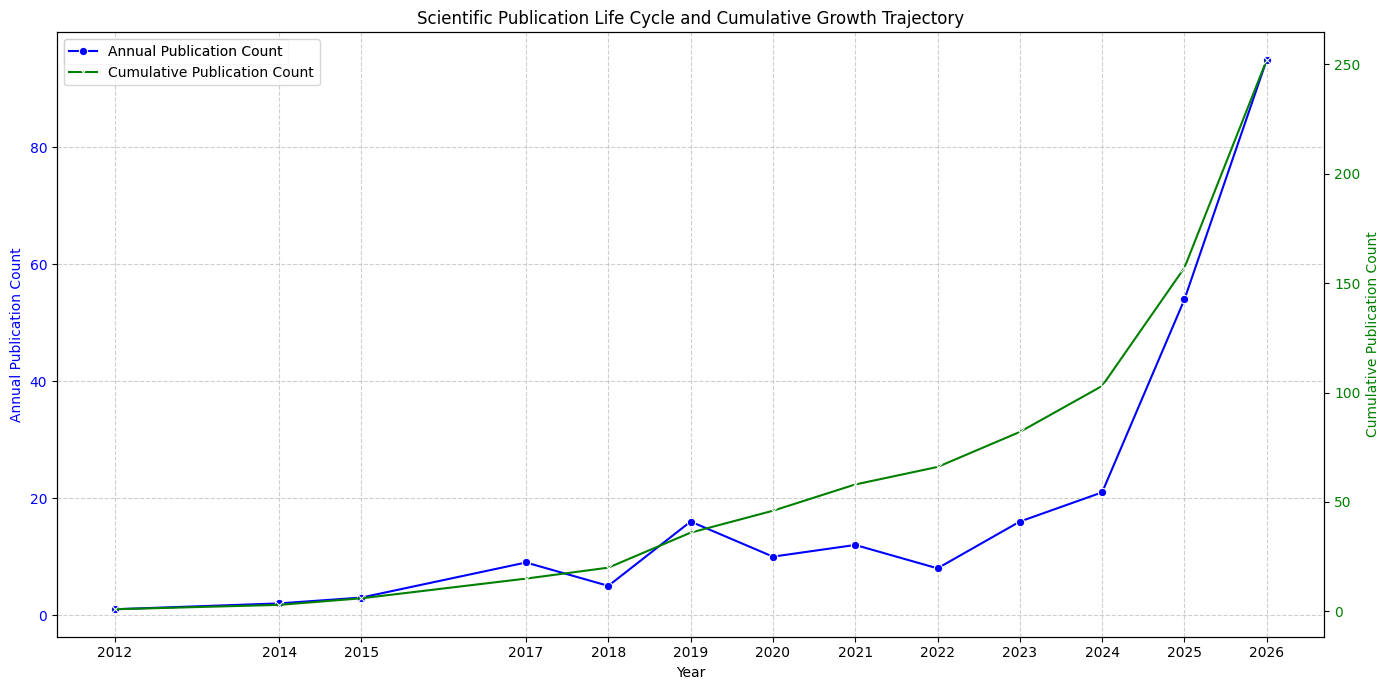

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate cumulative publication count
year_trend['Cumulative_Publication_Count'] = year_trend['Publication_Count'].cumsum()

# Create a figure with two subplots (sharing the x-axis for Year)
fig, ax1 = plt.subplots(figsize=(14, 7))

# Plot Annual Publication Count on the first y-axis (left)
sns.lineplot(x='Year', y='Publication_Count', data=year_trend, marker='o', ax=ax1, color='blue', label='Annual Publication Count')
ax1.set_xlabel('Year')
ax1.set_ylabel('Annual Publication Count', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')
ax1.set_title('Scientific Publication Life Cycle and Cumulative Growth Trajectory')
ax1.grid(True, linestyle='--', alpha=0.6)

# Create a second y-axis (right) for Cumulative Publication Count
ax2 = ax1.twinx()
sns.lineplot(x='Year', y='Cumulative_Publication_Count', data=year_trend, marker='x', ax=ax2, color='green', label='Cumulative Publication Count')
ax2.set_ylabel('Cumulative Publication Count', color='green')
ax2.tick_params(axis='y', labelcolor='green')

# Add legends for both lines
lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc='upper left')

plt.xticks(year_trend['Year'], rotation=45)
plt.tight_layout()
plt.show()

/tmp/ipykernel_469/2985417802.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Publication Count', y='Country', data=top_10_countries_df, palette='viridis')


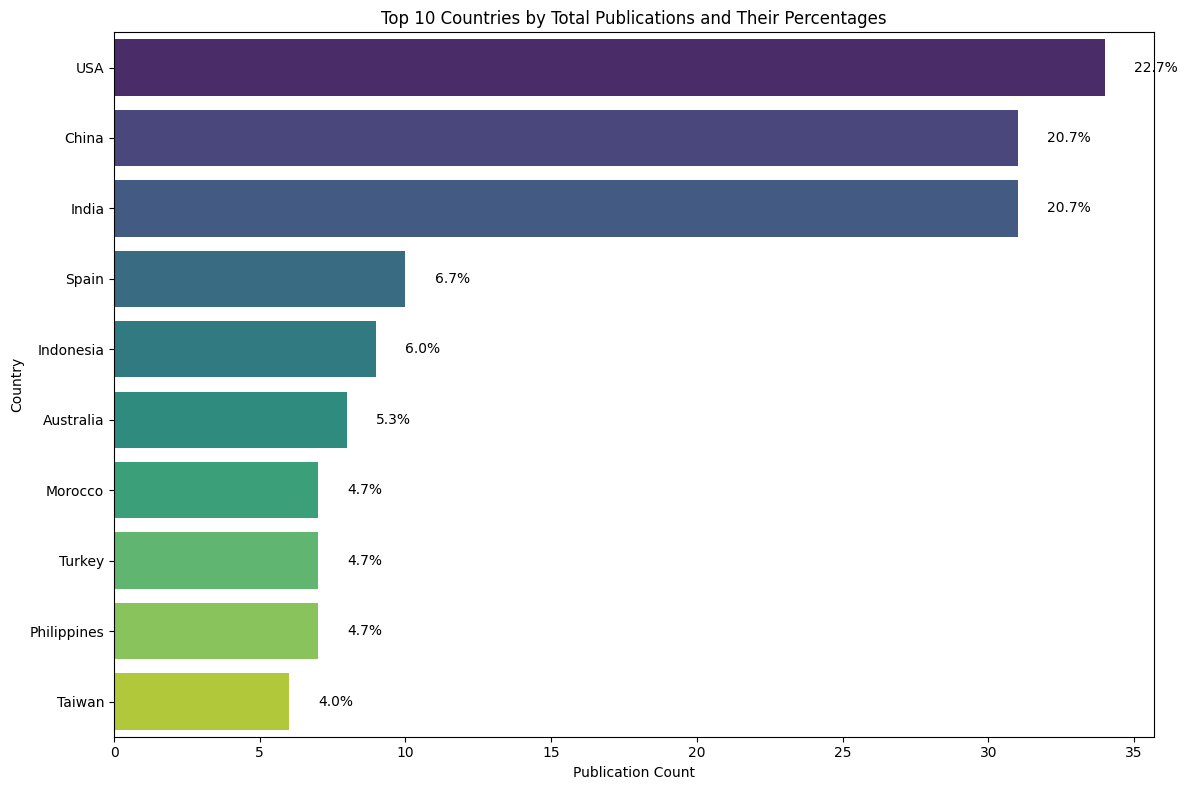

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure top_countries_df is available from previous steps
# If not, the previous code to generate it should be re-run or this cell should be combined.
# Assuming top_countries_df is already in the kernel state.

# Get the top 10 countries for this visualization
top_10_countries_df = top_countries_df.head(10).copy() # Use .copy() to avoid SettingWithCopyWarning

# Calculate the total publications for these top 10 countries to compute percentages
total_publications_top_10 = top_10_countries_df['Publication Count'].sum()

# Calculate the percentage for each of the top 10 countries
top_10_countries_df['Percentage'] = (top_10_countries_df['Publication Count'] / total_publications_top_10) * 100

# Plotting the top 10 countries with percentages
plt.figure(figsize=(12, 8))
sns.barplot(x='Publication Count', y='Country', data=top_10_countries_df, palette='viridis')
plt.title('Top 10 Countries by Total Publications and Their Percentages')
plt.xlabel('Publication Count')
plt.ylabel('Country')

# Add percentage labels to the bars
for index, row in top_10_countries_df.iterrows():
    plt.text(row['Publication Count'] + 1, index, f'{row['Percentage']:.1f}%', color='black', ha='left', va='center')

plt.tight_layout()
plt.show()

/tmp/ipykernel_469/110967305.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Publication Count', y='Funding Agency', data=top_funding_agencies_df, palette='rocket')


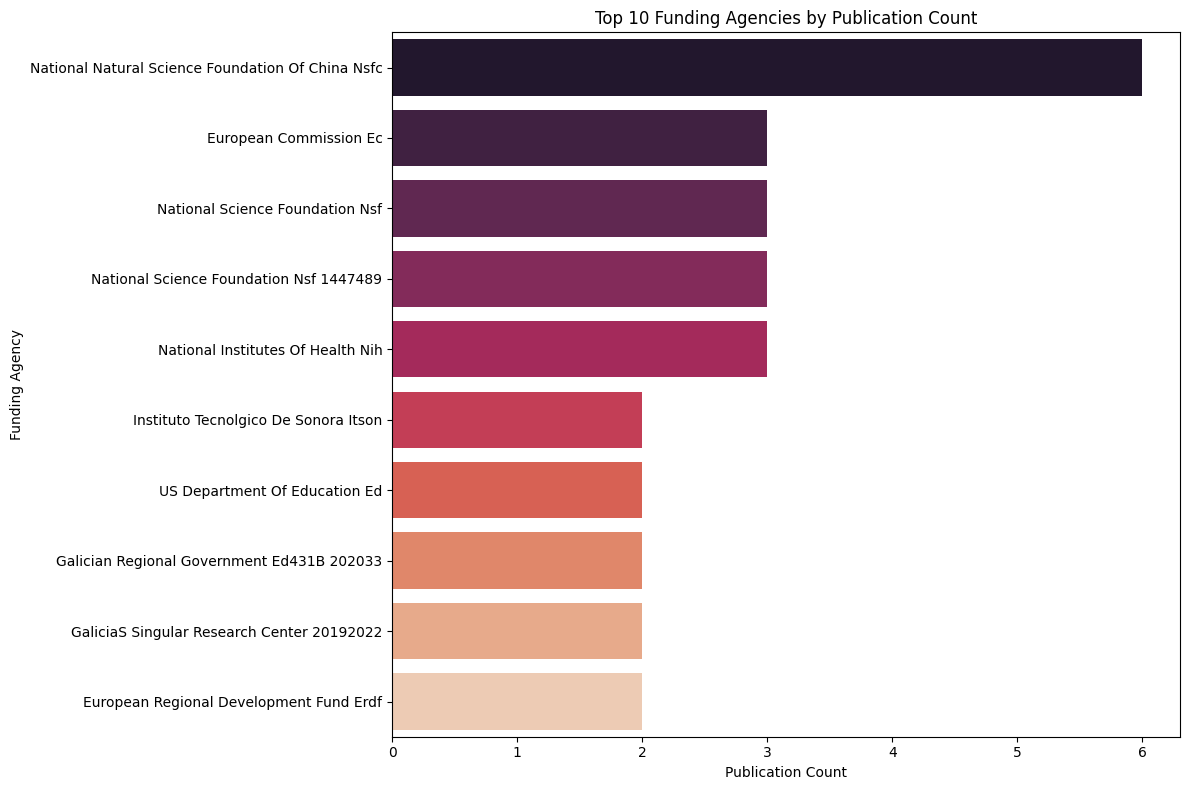

In [12]:
from collections import Counter
import re
import matplotlib.pyplot as plt
import seaborn as sns

# Drop rows where 'Funding Details' is NaN
funding_df = df.dropna(subset=['Funding Details']).copy()

all_funding_agencies = []
for funding_str in funding_df['Funding Details']:
    # Split by semicolon and clean each agency name
    agencies = [re.sub(r'[^a-zA-Z0-9 ]', '', f.strip().title()) for f in funding_str.split(';') if f.strip()]
    all_funding_agencies.extend(agencies)

# Count the frequency of each funding agency
funding_agency_counts = Counter(all_funding_agencies)

# Get the top 10 funding agencies
num_top_agencies = 10
top_funding_agencies = funding_agency_counts.most_common(num_top_agencies)

# Convert to DataFrame for easier plotting
top_funding_agencies_df = pd.DataFrame(top_funding_agencies, columns=['Funding Agency', 'Publication Count'])

# Plotting the top funding agencies
plt.figure(figsize=(12, 8))
sns.barplot(x='Publication Count', y='Funding Agency', data=top_funding_agencies_df, palette='rocket')
plt.title(f'Top {num_top_agencies} Funding Agencies by Publication Count')
plt.xlabel('Publication Count')
plt.ylabel('Funding Agency')
plt.tight_layout()
plt.show()

In [14]:
from collections import Counter, defaultdict
import re
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

# Function to extract country from an affiliation string (re-used for consistency)
def extract_country_from_affiliation(affiliation_str):
    parts = re.split(r'[,;]', affiliation_str)
    if parts:
        country = parts[-1].strip()
        country = re.sub(r'\([^)]*\)', '', country)
        country = re.sub(r'\d+', '', country)
        country = re.sub(r'[\\W_]+', ' ', country)
        country = country.strip().title()

        if 'Usa' in country: country = 'USA'
        elif 'United States' in country: country = 'USA'
        elif 'Uk' in country: country = 'UK'
        elif 'United Kingdom' in country: country = 'UK'
        elif 'Peoples R China' in country or 'Pr China' in country: country = 'China'
        elif 'Germany Federal Republic' in country: country = 'Germany'
        elif 'Korea South' in country: country = 'South Korea'

        if country and len(country) > 2 and not country.isdigit():
            return country
    return None

# --- Code to calculate author_counts (moved from cell_0940ede1 for self-containment) ---
# Drop rows where 'Authors' is NaN
authors_df_for_counts = df.dropna(subset=['Authors']).copy()

# Split authors and clean them
all_authors_for_counts = []
for authors_str in authors_df_for_counts['Authors']:
    authors_list = [author.strip() for author in authors_str.split(';') if author.strip()]
    all_authors_for_counts.extend(authors_list)

# Count the frequency of each author
author_counts = Counter(all_authors_for_counts)
# ---------------------------------------------------------------------------------------

# --- Code to calculate author_citations_df (moved from cell_9bb1e007 for self-containment) ---
# Create a dictionary to store total citations per author
author_citations = defaultdict(float)

# Iterate through each row of the DataFrame
for index, row in df.iterrows():
    authors_str = row['Authors']
    cited_by = row['Cited by']

    if pd.isna(authors_str) or pd.isna(cited_by):
        continue

    # Split the authors string by semicolon
    authors = [author.strip() for author in authors_str.split(';') if author.strip()]

    # Add the 'Cited by' count to each author
    for author in authors:
        author_citations[author] += cited_by

# Convert the dictionary to a DataFrame
author_citations_df = pd.DataFrame(author_citations.items(), columns=['Author', 'Total Citations'])
# --------------------------------------------------------------------------------------------------

# 1. Collect all authors and their publication counts (`tp_df`)
tp_df = pd.DataFrame(author_counts.items(), columns=['Author', 'Total Publications'])

# 2. Collect all authors and their total citations (`tc_df`)
# `author_citations_df` is now available from the block above.
tc_df = author_citations_df.copy()

# 3. Merge `tp_df` and `tc_df`
author_metrics_df = pd.merge(tp_df, tc_df, on='Author', how='left')
author_metrics_df['Total Citations'] = author_metrics_df['Total Citations'].fillna(0)

# 4. Calculate ACP (Average Citations Per Publication)
author_metrics_df['ACP'] = author_metrics_df['Total Citations'] / author_metrics_df['Total Publications']
author_metrics_df['ACP'] = author_metrics_df['ACP'].fillna(0) # Fill NaN for authors with 0 publications if any (unlikely here)

# 5. Determine Representative Affiliation
author_to_affiliations_map = defaultdict(list)
# Iterate through the original DataFrame `df` to link authors to paper affiliations
for _, row in df.iterrows():
    authors_in_paper = row['Authors']
    paper_affiliation = row['Affiliations']

    if pd.isna(authors_in_paper) or pd.isna(paper_affiliation):
        continue

    # Split authors string into a list of individual author names
    authors_list = [a.strip() for a in authors_in_paper.split(';') if a.strip()]

    # Associate the paper's full affiliation string with each author of that paper
    for author_name in authors_list:
        author_to_affiliations_map[author_name].append(paper_affiliation)

# For each author, find their most common (most frequent) associated affiliation string
most_common_affiliations = {}
for author, affiliations_list in author_to_affiliations_map.items():
    if affiliations_list:
        # Use Counter to find the most common affiliation string
        most_common_affiliations[author] = Counter(affiliations_list).most_common(1)[0][0]
    else:
        most_common_affiliations[author] = None # No affiliation found for this author

# Convert the most common affiliations dictionary to a DataFrame and merge with author_metrics_df
affiliations_for_merge_df = pd.DataFrame(most_common_affiliations.items(), columns=['Author', 'Affiliation'])
author_metrics_df = pd.merge(author_metrics_df, affiliations_for_merge_df, on='Author', how='left')

# Add Country column by extracting from Affiliation
author_metrics_df['Country'] = author_metrics_df['Affiliation'].apply(extract_country_from_affiliation)

# 6. Sort by Total Publications in descending order and Filter Top 20
author_metrics_df = author_metrics_df.sort_values(by='Total Publications', ascending=False)
num_top_authors = 20 # Changed from 10 to 20
top_authors_metrics_df = author_metrics_df.head(num_top_authors).copy()

# 7. Add Rank column
top_authors_metrics_df['Rank'] = range(1, len(top_authors_metrics_df) + 1)

# 8. Calculate TP (%) (percentage of publications within the top 20 authors)
total_pubs_top_authors = top_authors_metrics_df['Total Publications'].sum()
top_authors_metrics_df['TP (%)'] = (top_authors_metrics_df['Total Publications'] / total_pubs_top_authors * 100).round(2)

# 9. Reorder columns for the final display as requested
final_display_df = top_authors_metrics_df[['Rank', 'Author', 'Affiliation', 'Country', 'Total Publications', 'TP (%)', 'Total Citations', 'ACP']]

# 10. Display the resulting DataFrame
display(final_display_df)


TypeError: expected string or bytes-like object, got 'float'

In [15]:
import networkx as nx
import matplotlib.pyplot as plt

# Assuming final_display_df is available from the previous cell's execution
# If running this cell independently, ensure final_display_df is created.

G = nx.Graph()

# Add nodes for authors, affiliations, and countries
for index, row in final_display_df.iterrows():
    author = row['Author']
    affiliation = row['Affiliation']
    country = row['Country']
    total_publications = row['Total Publications']

    # Add author node (with publication count for sizing)
    G.add_node(author, node_type='Author', publications=total_publications)

    # Add affiliation node
    if pd.notna(affiliation):
        G.add_node(affiliation, node_type='Affiliation')
        # Add edge between author and affiliation
        G.add_edge(author, affiliation, edge_type='Author-Affiliation')

    # Add country node
    if pd.notna(country):
        G.add_node(country, node_type='Country')
        # Add edge between affiliation and country (if affiliation exists)
        if pd.notna(affiliation):
            G.add_edge(affiliation, country, edge_type='Affiliation-Country')
        # If no affiliation, directly link author to country (less common, but for completeness)
        else:
            G.add_edge(author, country, edge_type='Author-Country')

# Define node colors based on node type
node_colors = []
for node in G.nodes():
    if G.nodes[node]['node_type'] == 'Author':
        node_colors.append('skyblue')
    elif G.nodes[node]['node_type'] == 'Affiliation':
        node_colors.append('lightgreen')
    elif G.nodes[node]['node_type'] == 'Country':
        node_colors.append('salmon')

# Define node sizes based on author publications (only for author nodes)
node_sizes = []
for node in G.nodes():
    if G.nodes[node]['node_type'] == 'Author':
        # Scale publication count for better visualization
        node_sizes.append(G.nodes[node]['publications'] * 150)
    else:
        node_sizes.append(500) # Fixed size for affiliation and country nodes

plt.figure(figsize=(20, 15))
pos = nx.spring_layout(G, k=0.5, iterations=50, seed=42) # Layout for better visualization

# Draw nodes
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=node_sizes, alpha=0.9)

# Draw edges
nx.draw_networkx_edges(G, pos, edge_color='gray', alpha=0.5)

# Draw labels for all nodes
nx.draw_networkx_labels(G, pos, font_size=8, font_color='black', font_weight='bold')

plt.title('Network of Top 20 Authors, their Affiliations, and Countries', size=20)
plt.axis('off')
plt.show()


NameError: name 'final_display_df' is not defined

In [16]:
import plotly.graph_objects as go
import pandas as pd
import re
from collections import defaultdict

# Reuse the affiliation cleaning function for consistency
def extract_clean_institution(affiliation_str):
    patterns = [
        r'.*(?:University|Institute|College|Hospital|School|Center|Academy)\\b[^,]*', # e.g., University of XYZ, XYZ Institute
        r'[^,]+(?:Ltd|LLC|Inc|Corporation|Co)\\b', # Company names
        r'[^,]+' # Fallback: anything before the first comma
    ]

    for pattern in patterns:
        match = re.match(pattern, affiliation_str, re.IGNORECASE)
        if match:
            potential_institution = match.group(0).strip()
            potential_institution = re.sub(r'^(Department|Faculty|School|College|Center|Section) of\\s+', '', potential_institution, flags=re.IGNORECASE).strip()
            potential_institution = re.sub(r'\\s*(?:Inc|Ltd|LLC|Corporation|Co)\\b.*$', '', potential_institution, flags=re.IGNORECASE).strip()
            potential_institution = re.sub(r'\\s*\\([^)]*\\)$', '', potential_institution).strip()
            potential_institution = re.sub(r'\\s*\\d+$', '', potential_institution).strip()

            return potential_institution
    return affiliation_str.split(',')[0].strip()

# Prepare data for Sankey diagram
# `final_display_df` should be available from previous execution

labels = []
source = []
target = []
value = []

# Create unique lists of authors, cleaned affiliations, and countries
all_authors = final_display_df['Author'].tolist()

# Create a copy to avoid SettingWithCopyWarning
final_display_df_copy = final_display_df.copy()

# Clean affiliations from final_display_df_copy
final_display_df_copy['Clean Affiliation'] = final_display_df_copy['Affiliation'].apply(lambda x: extract_clean_institution(x) if pd.notna(x) else 'Unknown Affiliation')

all_clean_affiliations = final_display_df_copy['Clean Affiliation'].unique().tolist()
all_countries = final_display_df_copy['Country'].unique().tolist()
all_countries = [c for c in all_countries if pd.notna(c)] # Remove NaN countries

# Combine all unique entities for nodes
all_nodes = all_authors + all_clean_affiliations + all_countries
node_map = {node: i for i, node in enumerate(all_nodes)}

# Store aggregate publications per clean affiliation and country
affiliation_pubs = defaultdict(float)
country_pubs = defaultdict(float)

for index, row in final_display_df_copy.iterrows():
    author = row['Author']
    clean_affiliation = row['Clean Affiliation']
    country = row['Country']
    publications = row['Total Publications']

    # Link Author to Clean Affiliation
    source.append(node_map[author])
    target.append(node_map[clean_affiliation])
    value.append(publications)

    # Aggregate publications for each clean affiliation and country
    affiliation_pubs[clean_affiliation] += publications
    if pd.notna(country):
        country_pubs[country] += publications

# Link Clean Affiliation to Country (using aggregated publications for values)
# Iterate through unique affiliations and link them to their countries
for aff in all_clean_affiliations:
    # Find the representative country for this affiliation based on the first author using it
    # This is a simplification; a more robust approach might be needed for complex cases
    countries_for_this_aff = final_display_df_copy[final_display_df_copy['Clean Affiliation'] == aff]['Country'].dropna()
    if not countries_for_this_aff.empty:
        country_for_aff = countries_for_this_aff.mode()[0]
        if pd.notna(country_for_aff):
            source.append(node_map[aff])
            target.append(node_map[country_for_aff])
            # Use the sum of publications for this affiliation as the link value
            value.append(affiliation_pubs[aff])

# Sanity check: ensure all sources/targets are valid indices
if not all(isinstance(s, int) for s in source) or not all(isinstance(t, int) for t in target):
    print("Warning: Some source/target nodes are not mapped correctly to integers.")

# Plot the Sankey diagram
fig = go.Figure(data=[
    go.Sankey(
        node=dict(
            pad=15,
            thickness=20,
            line=dict(color="black", width=0.5),
            label=all_nodes,
            color=[
                'skyblue' if node in all_authors else
                'lightgreen' if node in all_clean_affiliations else
                'salmon' for node in all_nodes
            ]
        ),
        link=dict(
            source=source,
            target=target,
            value=value
        )
    )
])

fig.update_layout(title_text="Authors - Affiliation - Country Relationships", font_size=10, height=800, width=1200)
fig.show()

NameError: name 'final_display_df' is not defined

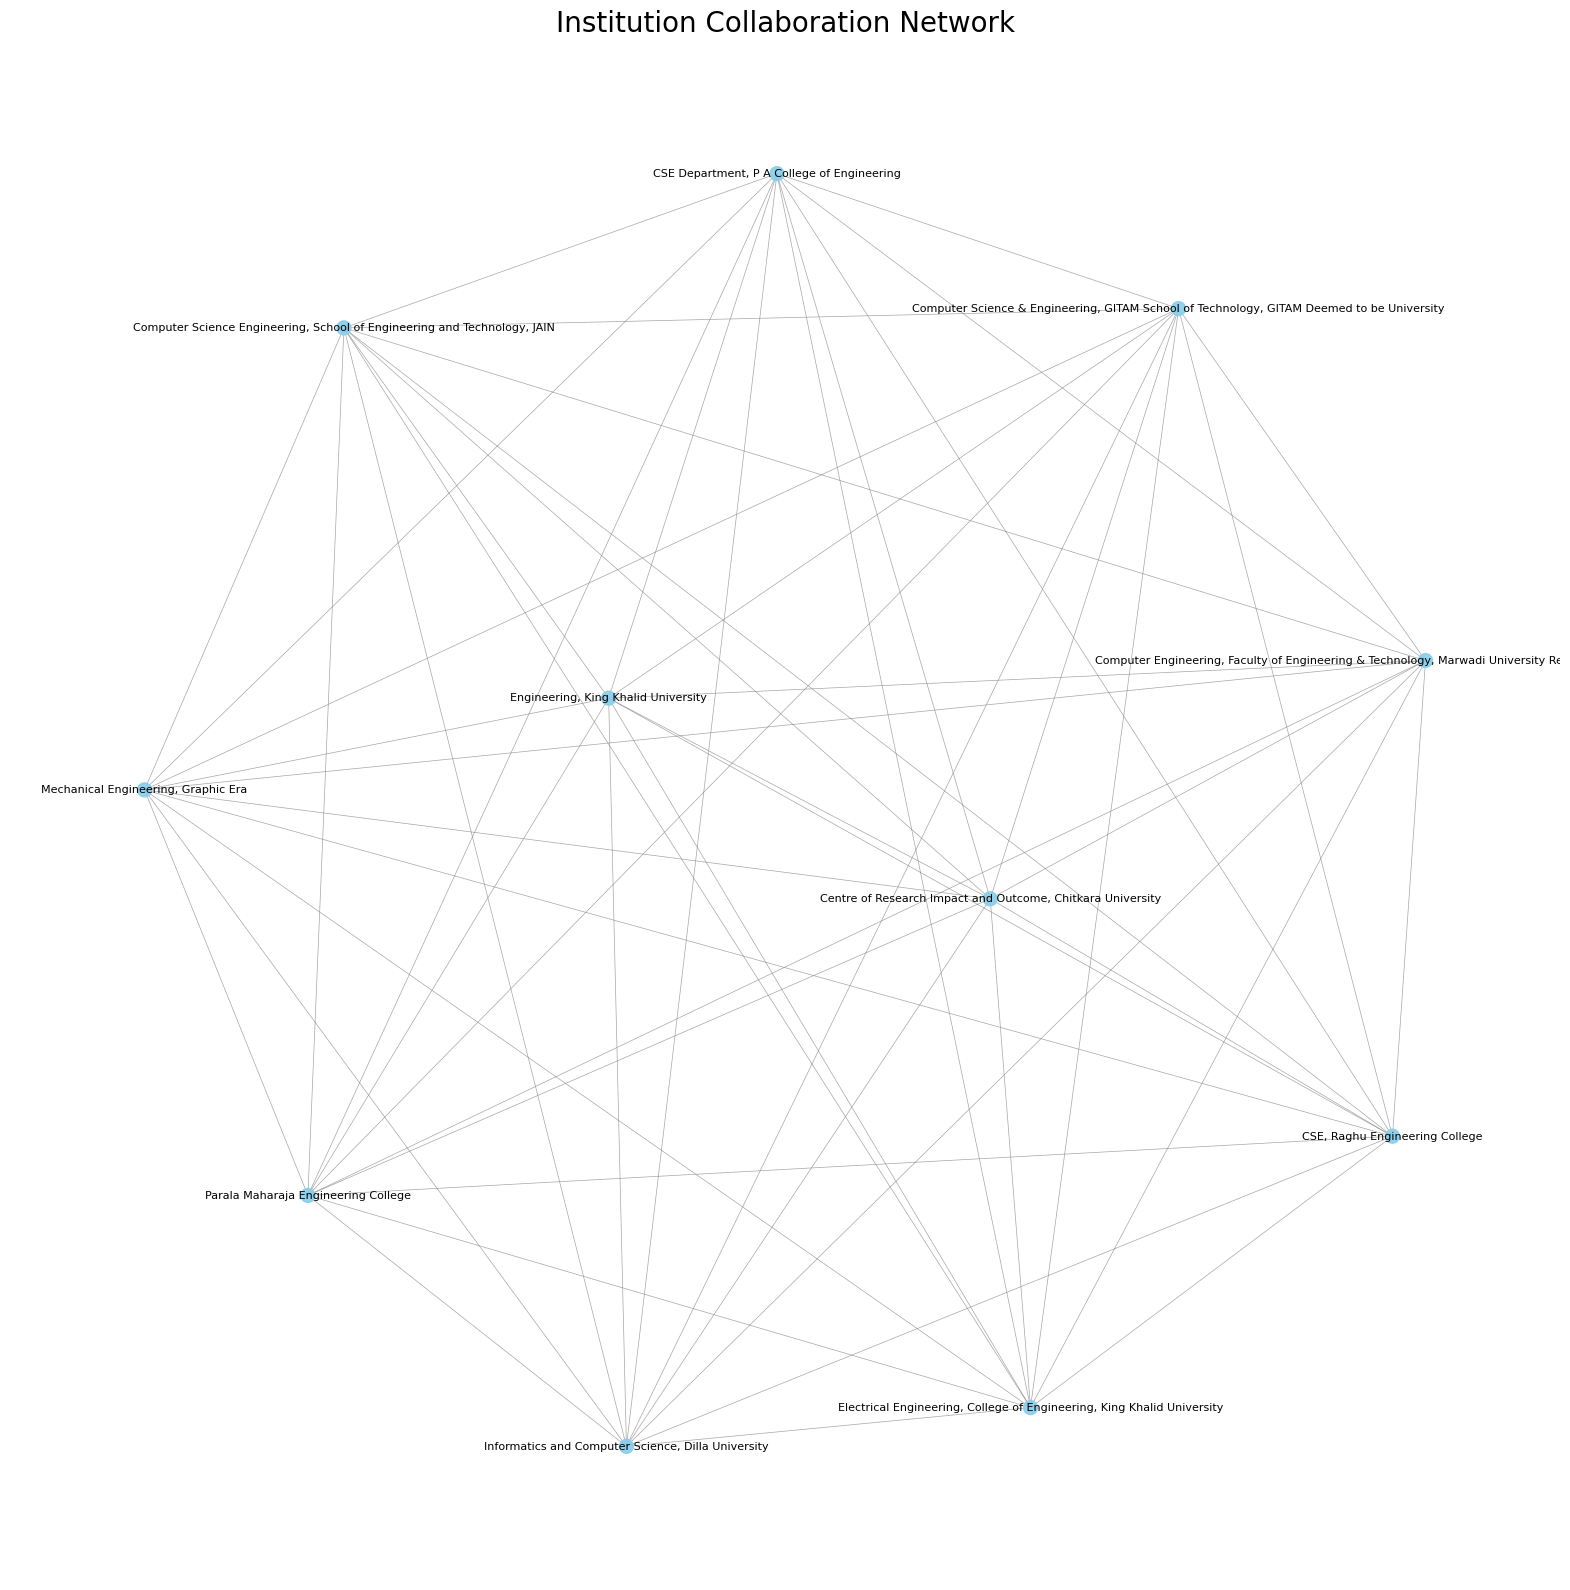

In [17]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
from collections import Counter, defaultdict
from itertools import combinations
import re

# --- Institution Collaboration Network Analysis ---

# Function to extract a cleaner institution name
def extract_clean_institution(affiliation_str):
    # This function attempts to extract a more generalized institution name.
    # It's a heuristic and might not be perfect for all cases.

    # Common patterns for institution names
    patterns = [
        r'.*(?:University|Institute|College|Hospital|School|Center|Academy)\b[^,]*', # e.g., University of XYZ, XYZ Institute
        r'[^,]+(?:Ltd|LLC|Inc|Corporation|Co)\b', # Company names
        r'[^,]+' # Fallback: anything before the first comma
    ]

    for pattern in patterns:
        match = re.match(pattern, affiliation_str, re.IGNORECASE)
        if match:
            potential_institution = match.group(0).strip()
            # Further cleaning: remove department/faculty prefixes, city/state suffixes
            potential_institution = re.sub(r'^(Department|Faculty|School|College|Center|Section) of\s+', '', potential_institution, flags=re.IGNORECASE).strip()
            # Remove any trailing "Inc", "Ltd", etc. if they are not part of the core name
            potential_institution = re.sub(r'\s*(?:Inc|Ltd|LLC|Corporation|Co)\b.*$', '', potential_institution, flags=re.IGNORECASE).strip()
            # Also remove anything in parentheses at the end
            potential_institution = re.sub(r'\s*\([^)]*\)$', '', potential_institution).strip()
            # Remove trailing numbers or specific project codes that sometimes appear
            potential_institution = re.sub(r'\s*\d+$', '', potential_institution).strip()

            return potential_institution

    # If no pattern matched, take the first part before a comma
    return affiliation_str.split(',')[0].strip()

# Drop rows where 'Affiliations' is NaN
affiliations_cleaned_df = df.dropna(subset=['Affiliations']).copy()

# Prepare a list of edges for institution collaborations
institution_collaborations = []
institution_publication_counts = defaultdict(int)

for _, row in affiliations_cleaned_df.iterrows():
    # Split the affiliations string into individual affiliation entries
    raw_affiliations = [aff.strip() for aff in row['Affiliations'].split(';') if aff.strip()]

    clean_institutions_in_paper = set()
    for aff in raw_affiliations:
        clean_inst = extract_clean_institution(aff)
        if clean_inst:
            clean_institutions_in_paper.add(clean_inst)
            institution_publication_counts[clean_inst] += 1 # Count publications per institution (at the cleaned level)

    # If there are multiple unique *cleaned* institutions, they are collaborating
    if len(clean_institutions_in_paper) > 1:
        for inst1, inst2 in combinations(clean_institutions_in_paper, 2):
            institution_collaborations.append(tuple(sorted((inst1, inst2)))) # Ensure consistent order for edges

# Filter out very common, generic terms if they somehow got through
# For example, "Taiwan", "China" could appear if not properly handled in regex
# Let's add a filter for institution names that are too short or look like country names
valid_institutions = {}
# A list of common country names to filter out if they mistakenly get parsed as institutions
common_countries = ['usa', 'uk', 'china', 'india', 'japan', 'france', 'germany', 'canada', 'italy', 'spain', 'australia', 'korea', 'taiwan', 'iran', 'malaysia', 'thailand', 'brazil', 'egypt', 'tunisia', 'poland', 'portugal', 'turkey', 'netherlands', 'belgium', 'switzerland', 'saudi arabia', 'sweden', 'pakistan', 'indonesia', 'vietnam', 'greece', 'finland', 'norway', 'mexico', 'colombia', 'argentina', 'chile', 'peru', 'south africa', 'nigeria', 'kenya', 'singapore', 'hong kong', 'united arab emirates', 'qatar', 'kuwait', 'israel', 'russia', 'ukraine', 'romania', 'hungary', 'czech republic', 'slovakia', 'bulgaria', 'serbia', 'croatia', 'slovenia', 'estonia', 'latvia', 'lithuania', 'ireland', 'denmark', 'austria', 'new zealand']

for inst, count in institution_publication_counts.items():
    if len(inst) > 5 and not inst.lower() in common_countries: # Filter out short names and common country names
        valid_institutions[inst] = count

# Re-filter collaborations based on valid institutions
filtered_institution_collaborations = []
for inst1, inst2 in institution_collaborations:
    if inst1 in valid_institutions and inst2 in valid_institutions:
        filtered_institution_collaborations.append(tuple(sorted((inst1, inst2))))

# Count the frequency of each collaboration
collaboration_counts = Counter(filtered_institution_collaborations)

# Create a graph
G_institutions = nx.Graph()

# Add nodes and edges to the graph
for (inst1, inst2), weight in collaboration_counts.items():
    G_institutions.add_edge(inst1, inst2, weight=weight)

# Filter out institutions that are not connected to anything or have very few publications
if len(G_institutions.nodes()) > 0:
    # Keep only the largest connected component (often more meaningful for dense graphs)
    components = list(nx.connected_components(G_institutions))
    if components:
        largest_component = max(components, key=len)
        G_institutions = G_institutions.subgraph(largest_component)

if not G_institutions.nodes():
    print("No significant institution collaboration network could be formed after filtering.")
else:
    # Recalculate node sizes for the filtered graph
    node_sizes_institutions = [valid_institutions.get(node, 0) * 100 for node in G_institutions.nodes()] # Scale for better visibility
    edge_widths_institutions = [G_institutions[u][v]['weight'] * 0.5 for u, v in G_institutions.edges()] # Scale for better visibility

    # Draw the network
    plt.figure(figsize=(20, 20)) # Increased size for better readability
    pos_institutions = nx.spring_layout(G_institutions, k=0.3, iterations=50) # Positions nodes

    nx.draw_networkx_nodes(G_institutions, pos_institutions, node_size=node_sizes_institutions, node_color='skyblue', alpha=0.9)
    nx.draw_networkx_edges(G_institutions, pos_institutions, width=edge_widths_institutions, edge_color='gray', alpha=0.7)
    nx.draw_networkx_labels(G_institutions, pos_institutions, font_size=8, font_color='black')

    plt.title('Institution Collaboration Network', size=20)
    plt.axis('off')
    plt.show()

### Methodology for Institution and Country Collaboration Visualizations

**Institution Collaboration Network:**
To create the institution collaboration network, I've implemented a heuristic-based `extract_clean_institution` function to parse the `Affiliations` column. This function attempts to generalize detailed affiliation strings (e.g., 'Department of X, University of Y') into a more consolidated institution name (e.g., 'University of Y'). This is an inherently challenging task due to the varied and often unstructured nature of affiliation data, so while efforts are made to clean and consolidate, some inconsistencies or very specific department-level nodes might still appear.

*   **Nodes**: Represent cleaned institution names.
*   **Edges**: Connect institutions that have co-authored at least one paper.
*   **Node Size**: Scaled by the total number of publications associated with that institution.
*   **Edge Width**: Scaled by the frequency of collaboration between two institutions.
*   **Filtering**: The network is filtered to show only the largest connected component and institutions with sufficiently long and non-generic names to reduce clutter.

**Country Collaboration Network:**
For country collaborations, I've reused the robust country extraction logic from earlier analysis to identify unique countries involved in each publication.

*   **Nodes**: Represent country names.
*   **Edges**: Connect countries that have co-authored at least one paper.
*   **Node Size**: Scaled by the total number of publications associated with that country.
*   **Edge Width**: Scaled by the frequency of collaboration between two countries.

**Country Overlay Visualization:**
This visualization maps the collaboration data onto a world map.

*   **Map**: A standard world map from `geopandas`.
*   **Color Intensity**: Countries are colored based on their total collaboration strength (sum of weights of all collaboration edges involving that country). Darker shades indicate higher collaboration activity.


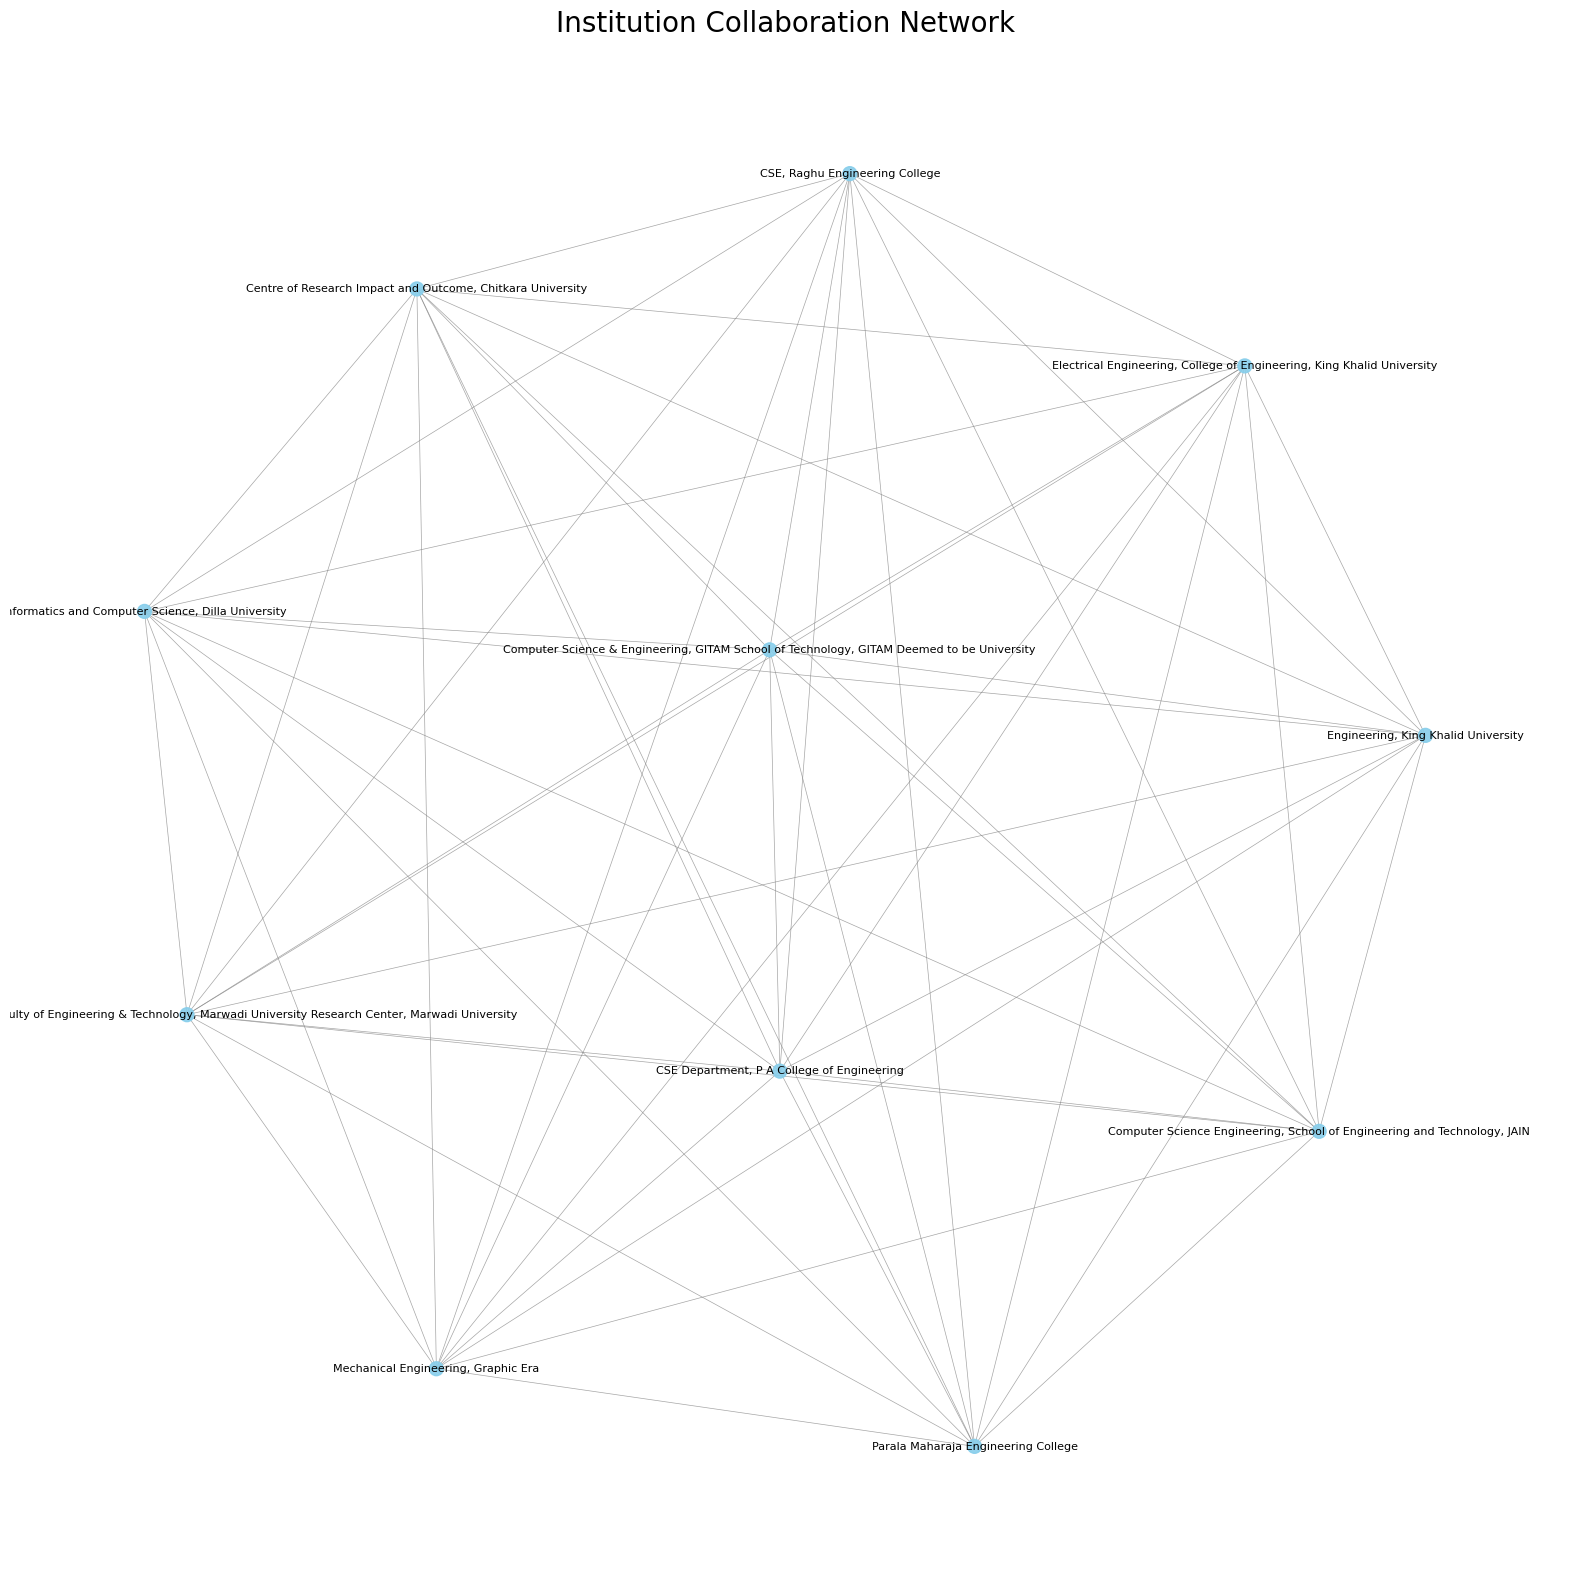

In [18]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
from collections import Counter, defaultdict
from itertools import combinations
import re

# --- Institution Collaboration Network Analysis ---

# Function to extract a cleaner institution name
def extract_clean_institution(affiliation_str):
    # This function attempts to extract a more generalized institution name.
    # It's a heuristic and might not be perfect for all cases.

    # Common patterns for institution names
    patterns = [
        r'.*(?:University|Institute|College|Hospital|School|Center|Academy)\b[^,]*', # e.g., University of XYZ, XYZ Institute
        r'[^,]+(?:Ltd|LLC|Inc|Corporation|Co)\b', # Company names
        r'[^,]+' # Fallback: anything before the first comma
    ]

    for pattern in patterns:
        match = re.match(pattern, affiliation_str, re.IGNORECASE)
        if match:
            potential_institution = match.group(0).strip()
            # Further cleaning: remove department/faculty prefixes, city/state suffixes
            potential_institution = re.sub(r'^(Department|Faculty|School|College|Center|Section) of\s+', '', potential_institution, flags=re.IGNORECASE).strip()
            # Remove any trailing "Inc", "Ltd", etc. if they are not part of the core name
            potential_institution = re.sub(r'\s*(?:Inc|Ltd|LLC|Corporation|Co)\b.*$', '', potential_institution, flags=re.IGNORECASE).strip()
            # Also remove anything in parentheses at the end
            potential_institution = re.sub(r'\s*\([^)]*\)$', '', potential_institution).strip()
            # Remove trailing numbers or specific project codes that sometimes appear
            potential_institution = re.sub(r'\s*\d+$', '', potential_institution).strip()

            return potential_institution

    # If no pattern matched, take the first part before a comma
    return affiliation_str.split(',')[0].strip()

# Drop rows where 'Affiliations' is NaN
affiliations_cleaned_df = df.dropna(subset=['Affiliations']).copy()

# Prepare a list of edges for institution collaborations
institution_collaborations = []
institution_publication_counts = defaultdict(int)

for _, row in affiliations_cleaned_df.iterrows():
    # Split the affiliations string into individual affiliation entries
    raw_affiliations = [aff.strip() for aff in row['Affiliations'].split(';') if aff.strip()]

    clean_institutions_in_paper = set()
    for aff in raw_affiliations:
        clean_inst = extract_clean_institution(aff)
        if clean_inst:
            clean_institutions_in_paper.add(clean_inst)
            institution_publication_counts[clean_inst] += 1 # Count publications per institution (at the cleaned level)

    # If there are multiple unique *cleaned* institutions, they are collaborating
    if len(clean_institutions_in_paper) > 1:
        for inst1, inst2 in combinations(clean_institutions_in_paper, 2):
            institution_collaborations.append(tuple(sorted((inst1, inst2)))) # Ensure consistent order for edges

# Filter out very common, generic terms if they somehow got through
# For example, "Taiwan", "China" could appear if not properly handled in regex
# Let's add a filter for institution names that are too short or look like country names
valid_institutions = {}
# A list of common country names to filter out if they mistakenly get parsed as institutions
common_countries = ['usa', 'uk', 'china', 'india', 'japan', 'france', 'germany', 'canada', 'italy', 'spain', 'australia', 'korea', 'taiwan', 'iran', 'malaysia', 'thailand', 'brazil', 'egypt', 'tunisia', 'poland', 'portugal', 'turkey', 'netherlands', 'belgium', 'switzerland', 'saudi arabia', 'sweden', 'pakistan', 'indonesia', 'vietnam', 'greece', 'finland', 'norway', 'mexico', 'colombia', 'argentina', 'chile', 'peru', 'south africa', 'nigeria', 'kenya', 'singapore', 'hong kong', 'united arab emirates', 'qatar', 'kuwait', 'israel', 'russia', 'ukraine', 'romania', 'hungary', 'czech republic', 'slovakia', 'bulgaria', 'serbia', 'croatia', 'slovenia', 'estonia', 'latvia', 'lithuania', 'ireland', 'denmark', 'austria', 'new zealand']

for inst, count in institution_publication_counts.items():
    if len(inst) > 5 and not inst.lower() in common_countries: # Filter out short names and common country names
        valid_institutions[inst] = count

# Re-filter collaborations based on valid institutions
filtered_institution_collaborations = []
for inst1, inst2 in institution_collaborations:
    if inst1 in valid_institutions and inst2 in valid_institutions:
        filtered_institution_collaborations.append(tuple(sorted((inst1, inst2))))

# Count the frequency of each collaboration
collaboration_counts = Counter(filtered_institution_collaborations)

# Create a graph
G_institutions = nx.Graph()

# Add nodes and edges to the graph
for (inst1, inst2), weight in collaboration_counts.items():
    G_institutions.add_edge(inst1, inst2, weight=weight)

# Filter out institutions that are not connected to anything or have very few publications
if len(G_institutions.nodes()) > 0:
    # Keep only the largest connected component (often more meaningful for dense graphs)
    components = list(nx.connected_components(G_institutions))
    if components:
        largest_component = max(components, key=len)
        G_institutions = G_institutions.subgraph(largest_component)

if not G_institutions.nodes():
    print("No significant institution collaboration network could be formed after filtering.")
else:
    # Recalculate node sizes for the filtered graph
    node_sizes_institutions = [valid_institutions.get(node, 0) * 100 for node in G_institutions.nodes()] # Scale for better visibility
    edge_widths_institutions = [G_institutions[u][v]['weight'] * 0.5 for u, v in G_institutions.edges()] # Scale for better visibility

    # Draw the network
    plt.figure(figsize=(20, 20)) # Increased size for better readability
    pos_institutions = nx.spring_layout(G_institutions, k=0.3, iterations=50) # Positions nodes

    nx.draw_networkx_nodes(G_institutions, pos_institutions, node_size=node_sizes_institutions, node_color='skyblue', alpha=0.9)
    nx.draw_networkx_edges(G_institutions, pos_institutions, width=edge_widths_institutions, edge_color='gray', alpha=0.7)
    nx.draw_networkx_labels(G_institutions, pos_institutions, font_size=8, font_color='black')

    plt.title('Institution Collaboration Network', size=20)
    plt.axis('off')
    plt.show()

In [19]:
import requests
import zipfile
import io
import os

# URL for the natural earth lowres dataset
# Updated to a direct Amazon S3 link for better reliability
download_url = "https://naturalearth.s3.amazonaws.com/110m_cultural/ne_110m_admin_0_countries.zip"

# Define the directory to extract files to
output_dir = "./ne_110m_admin_0_countries"

# Create the directory if it doesn't exist
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

# Add a User-Agent header to mimic a browser request
headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36'}

# Download the zip file with headers
print(f"Downloading from {download_url}")
response = requests.get(download_url, headers=headers)
response.raise_for_status() # Raise an exception for HTTP errors

# Extract the zip file
with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    z.extractall(output_dir)

print(f"Dataset extracted to {output_dir}")

# Update the path to the shapefile
world_map_path = os.path.join(output_dir, "ne_110m_admin_0_countries.shp")

Dataset extracted to ./ne_110m_admin_0_countries


In [20]:
import geopandas
import matplotlib.pyplot as plt
import pandas as pd
from collections import defaultdict

# --- Country Overlay Visualization ---

# Load the world map data from the downloaded shapefile
# The 'world_map_path' variable is set in the previous cell after download and extraction.
world = geopandas.read_file(world_map_path)

# total_collaborations_per_country - calculated from the G_countries graph
total_collaborations_per_country = defaultdict(int)
for node in G_countries.nodes():
    # Sum of weights of all edges connected to this node
    total_collaborations_per_country[node] = sum(G_countries[node][neighbor]['weight'] for neighbor in G_countries.neighbors(node))

# Convert to DataFrame for merging
collaborations_df = pd.DataFrame(list(total_collaborations_per_country.items()), columns=['Country', 'Total Collaborations'])

# Standardize country names in the world map and our data to facilitate merging
# GeoPandas 'naturalearth_lowres' dataset uses specific country names.
# We need to map our extracted country names to those used in the GeoPandas dataframe.
country_name_mapping = {
    'USA': 'United States of America',
    'UK': 'United Kingdom',
    'China': 'China',
    'South Korea': 'Republic of Korea',
    'Iran': 'Iran',
    'Germany': 'Germany',
    'Canada': 'Canada',
    'France': 'France',
    'India': 'India',
    'Japan': 'Japan',
    'Australia': 'Australia',
    'Malaysia': 'Malaysia',
    'Belgium': 'Belgium',
    'Italy': 'Italy',
    'Turkey': 'Turkey',
    'Netherlands': 'Netherlands',
    'Portugal': 'Portugal',
    'Spain': 'Spain',
    'Brazil': 'Brazil',
    'Egypt': 'Egypt',
    'Taiwan': 'Taiwan', # Taiwan might not be in naturalearth_lowres as a separate entity
    'Tunisia': 'Tunisia',
    'Indonesia': 'Indonesia',
    'Switzerland': 'Switzerland',
    'Poland': 'Poland',
    'Sweden': 'Sweden',
    'Pakistan': 'Pakistan',
    'Vietnam': 'Vietnam',
    'Singapore': 'Singapore',
    'Saudi Arabia': 'Saudi Arabia',
    'Greece': 'Greece',
    'Hong Kong': 'Hong Kong',
    'Ireland': 'Ireland',
    'Denmark': 'Denmark',
    'Austria': 'Austria',
    'Chile': 'Chile',
    'Colombia': 'Colombia',
    'Finland': 'Finland',
    'Hungary': 'Hungary',
    'Mexico': 'Mexico',
    'Nigeria': 'Nigeria',
    'New Zealand': 'New Zealand',
    'Norway': 'Norway',
    'Romania': 'Romania',
    'Russia': 'Russia',
    'Slovakia': 'Slovakia',
    'South Africa': 'South Africa',
    'Ukraine': 'Ukraine',
    'Argentina': 'Argentina',
    'Bulgaria': 'Bulgaria',
    'Czech Republic': 'Czech Republic',
    'Croatia': 'Croatia',
    'Ethiopia': 'Ethiopia',
    'Jordan': 'Jordan',
    'Peru': 'Peru',
    'Qatar': 'Qatar',
    'Serbia': 'Serbia',
    'Slovenia': 'Slovenia',
    'Thailand': 'Thailand',
    'United Arab Emirates': 'United Arab Emirates',
    'Uzbekistan': 'Uzbekistan'
}

collaborations_df['Country_Geo'] = collaborations_df['Country'].map(country_name_mapping)

# Merge with world map data using the correct column name, e.g., 'NAME' or 'ADMIN'
# Let's try 'NAME' first, as it's common for naturalearth_lowres
world_with_collaborations = world.merge(collaborations_df, left_on='NAME', right_on='Country_Geo', how='left')

# Fill NaN collaborations with 0 for countries not in our dataset
world_with_collaborations['Total Collaborations'] = world_with_collaborations['Total Collaborations'].fillna(0)

# Plotting the overlay visualization for countries
fig, ax = plt.subplots(1, 1, figsize=(15, 10))
world_with_collaborations.plot(column='Total Collaborations', cmap='OrRd', linewidth=0.8, ax=ax, edgecolor='0.8', legend=True,
                               legend_kwds={'label': "Total Collaboration Strength",
                                            'orientation': "horizontal"})
ax.set_title('Country Collaboration Overlay Visualization', size=20)
ax.set_axis_off()
plt.show()

NameError: name 'G_countries' is not defined

In [22]:
# Upload file from local computer (if not already uploaded in this session)
from google.colab import files

print("Please upload 'HealthCareSystem.csv' if prompted. If it was already uploaded in this session, you can skip this step.")
uploaded = files.upload()

# Import pandas
import pandas as pd

# Load the uploaded file
df = pd.read_csv("big_data.csv")

# Show first 5 rows to confirm loading
print("DataFrame 'df' loaded successfully:")
display(df.head())

Please upload 'HealthCareSystem.csv' if prompted. If it was already uploaded in this session, you can skip this step.


Saving big_data.csv to big_data (2).csv
DataFrame 'df' loaded successfully:


,Authors,Author full names,Author(s) ID,Title,Year,Source title,Volume,Issue,Art. No.,Page start,...,ISBN,CODEN,PubMed ID,Language of Original Document,Abbreviated Source Title,Document Type,Publication Stage,Open Access,Source,EID
0,Ajaegbo N.G.; Prasad R.; Abdullahi H.I.; Awoke O.,"Ajaegbo, Nkechi Gloria (60730247700); Prasad, ...",60730247700; 57191422092; 60730231800; 5971624...,A Computational Framework for Inclusive Assess...,2026,Student Enrollment and Retention Strategies to...,NaN,NaN,NaN,95,...,979-833737948-7; 979-833737946-3; 979-833737947-0,NaN,NaN,English,Student Enrollment and Retention Strategies to...,Book chapter,Final,NaN,Scopus,2-s2.0-105044124063
1,Hong Y.Z.; Rani M.N.A.; Radzuan N.F.M.; Yen L....,"Hong, Yam Zheng (59522138000); Rani, Mohd Nors...",59522138000; 57280898600; 57280264100; 5952149...,AN EARLY WARNING SYSTEM FOR STUDENTS AT RISK U...,2024,Journal of Engineering Science and Technology,19,1,NaN,131,...,NaN,NaN,NaN,English,J. Eng. Sci. Technol.,Article,Final,NaN,Scopus,2-s2.0-85199341707
2,Ewais A.; Arram A.; Diab S.; Alkhazaleh H.A.; ...,"Ewais, Ahmed. (35179213000); Arram, Anas (5639...",35179213000; 56394464200; 57219508139; 5966242...,Using machine learning for early identificatio...,2026,Scientific Reports,16,1,19944,NaN,...,NaN,NaN,42031821.0,English,Sci. Rep.,Article,Final,All Open Access; Gold Open Access,Scopus,2-s2.0-105043648818
3,Gu W.; Yang F.; Li W.; Wang Z.; Zhu Z.,"Gu, Wenyuan (60207267700); Yang, Fanfan (60503...",60207267700; 60503003900; 60503792000; 6017738...,Intelligent monitoring system for hazardous so...,2025,Experimental Technology and Management,42,12,NaN,238,...,NaN,NaN,NaN,Chinese,Exp. Tech. Manag.,Article,Final,NaN,Scopus,2-s2.0-105032794504
4,Dhanalakshmi B.; Chakresh N.K.; Indhuja V.,"Dhanalakshmi, B. (57282085000); Chakresh, N.K....",57282085000; 60607270700; 58069227800,A Data-Driven Software Framework to Predict an...,2025,ICRTEECT 2025 - 2nd International Conference o...,NaN,NaN,NaN,NaN,...,979-833158172-5,NaN,NaN,English,"ICRTEECT - Int. Conf. Recent Trends Electr., E...",Conference paper,Final,NaN,Scopus,2-s2.0-105037326377


The `df` DataFrame has been loaded. Now you can re-run the cell for the Bibliographic Coupling Analysis of Top 20 Countries (`cell_id: 5bc24558`).

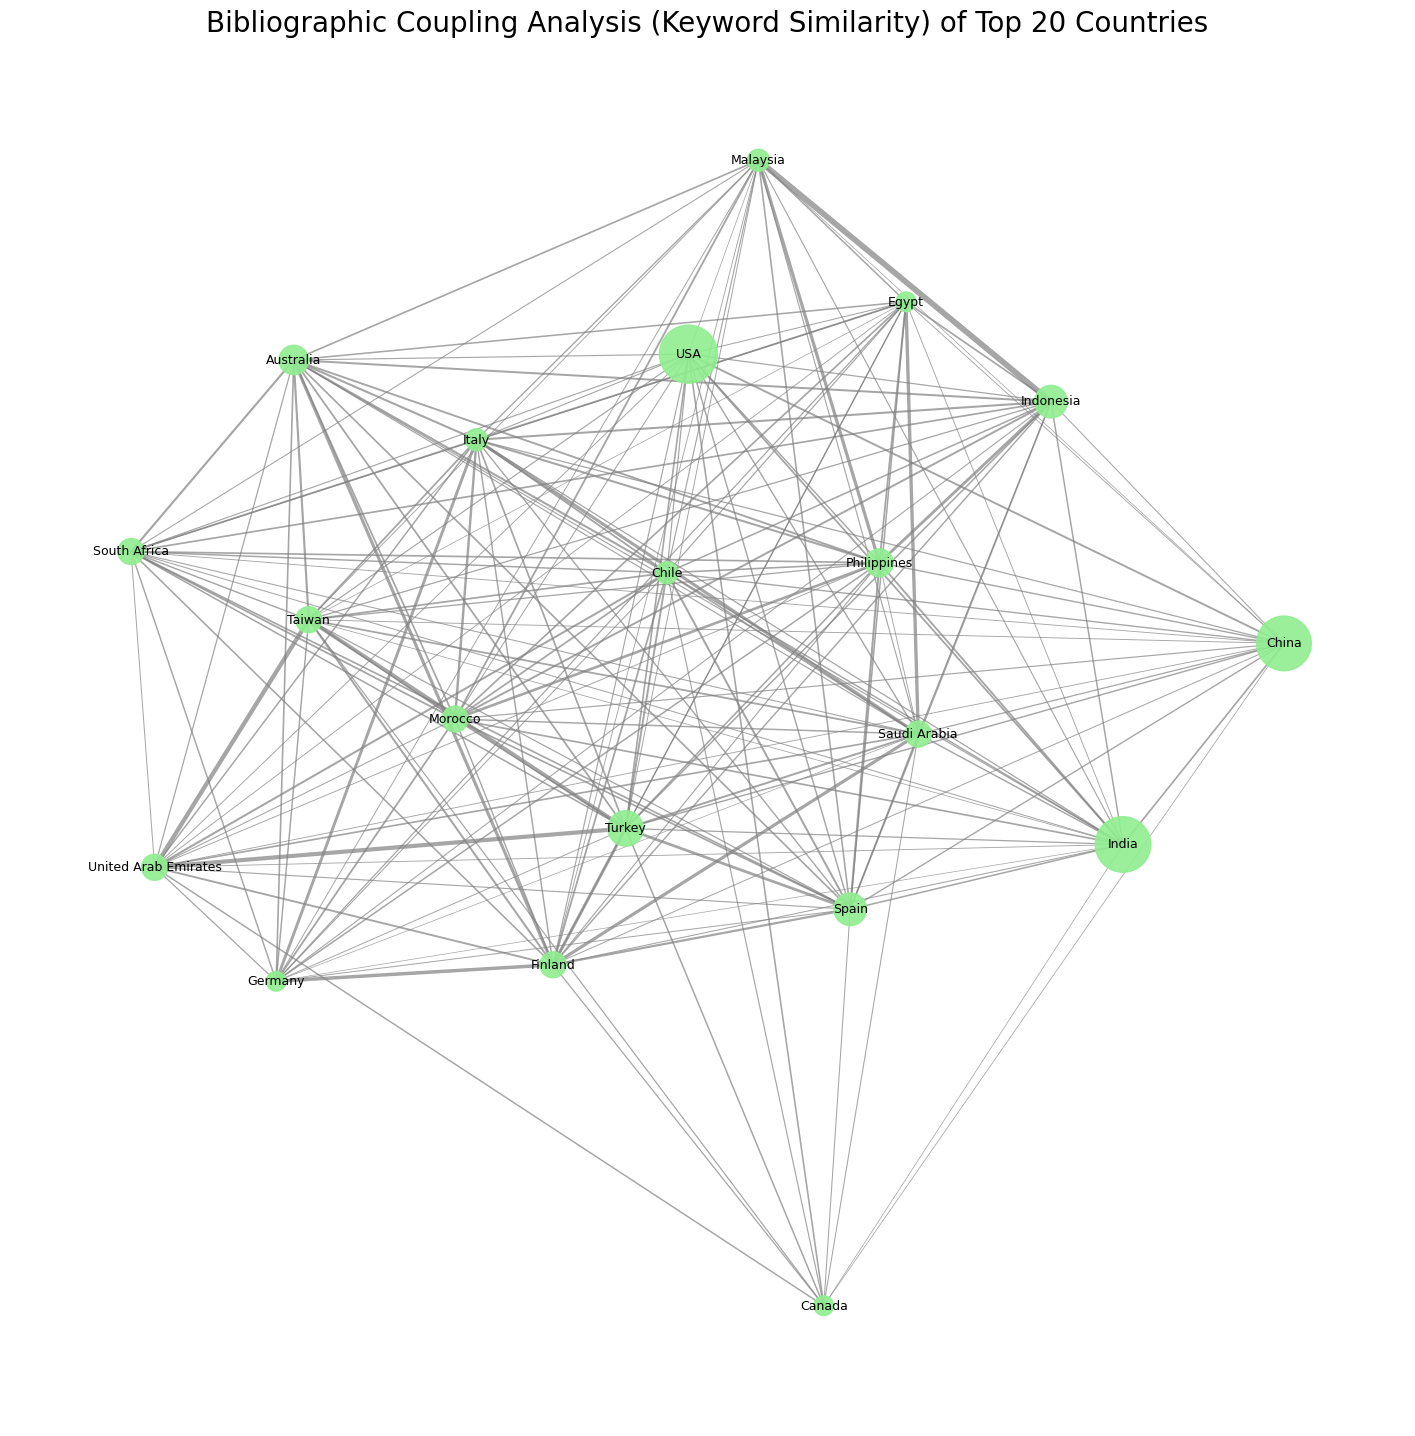

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import pandas as pd
from collections import Counter, defaultdict
from itertools import combinations
import re

# --- Load DataFrame 'df' (added for robustness) ---
try:
    # Attempt to access 'df' to see if it's already defined
    df.head()
except NameError:
    # If 'df' is not defined, load it from the CSV file
    print("DataFrame 'df' not found, attempting to load 'HealthCareSystem.csv'.")
    # Assuming 'HealthCareSystem.csv' is available in the current directory
    # If not, files.upload() would be needed for interactive use.
    df = pd.read_csv("HealthCareSystem.csv")
    print("DataFrame 'df' loaded.")

# --- Preprocessing 'Cited by', 'Year', and 'Open Access Simplified' (copied from previous cells) ---
# Convert 'Cited by' to numeric, filling NaNs with 0
df['Cited by'] = pd.to_numeric(df['Cited by'], errors='coerce').fillna(0)

# Convert 'Year' to numeric, filling NaNs with the median year
df['Year'] = pd.to_numeric(df['Year'], errors='coerce')
median_year = df['Year'].median()
df['Year'] = df['Year'].fillna(median_year).astype(int)

# Simplify 'Open Access' column
def classify_open_access(value):
    if pd.isna(value):
        return 'Not Open Access'
    elif 'Open Access' in value:
        return 'Open Access'
    else:
        return 'Not Open Access'

df['Open Access Simplified'] = df['Open Access'].apply(classify_open_access)


# --- Function to extract country from an affiliation string (re-used from previous analysis) ---
def extract_country_from_affiliation(affiliation_str):
    parts = re.split(r'[,;]', affiliation_str)
    if parts:
        country = parts[-1].strip()
        country = re.sub(r'\\([^)]*\\)', '', country)
        country = re.sub(r'\\d+', '', country)
        country = re.sub(r'[\\W_]+', ' ', country)
        country = country.strip().title()

        if 'Usa' in country: country = 'USA'
        elif 'United States' in country: country = 'USA'
        elif 'Uk' in country: country = 'UK'
        elif 'United Kingdom' in country: country = 'UK'
        elif 'Peoples R China' in country or 'Pr China' in country: country = 'China'
        elif 'Germany Federal Republic' in country: country = 'Germany'
        elif 'Korea South' in country: country = 'South Korea'

        if country and len(country) > 2 and not country.isdigit():
            return country
    return None

# --- Calculate country publication counts (re-used for consistent top countries selection) ---
affiliations_df_for_countries = df.dropna(subset=['Affiliations']).copy()
country_publication_counts = defaultdict(int)

for _, row in affiliations_df_for_countries.iterrows():
    all_raw_affiliations = [aff.strip() for aff in row['Affiliations'].split(';') if aff.strip()]
    countries_in_paper = set()
    for aff in all_raw_affiliations:
        country = extract_country_from_affiliation(aff)
        if country:
            countries_in_paper.add(country)
    for country in countries_in_paper:
        country_publication_counts[country] += 1

# Get the top 20 countries by publication count
country_pub_counts_df = pd.DataFrame(list(country_publication_counts.items()), columns=['Country', 'Publication Count'])
top_20_countries = country_pub_counts_df.nlargest(20, 'Publication Count')['Country'].tolist()

# --- Extract country-specific keywords for the top 20 countries ---
country_keywords = defaultdict(set)
for _, row in df.iterrows():
    # Get countries associated with this paper
    paper_countries = set()
    if not pd.isna(row['Affiliations']):
        raw_affiliations = [aff.strip() for aff in row['Affiliations'].split(';') if aff.strip()]
        for aff in raw_affiliations:
            country = extract_country_from_affiliation(aff)
            if country and country in top_20_countries: # Only consider keywords for papers from our top 20 countries
                paper_countries.add(country)

    # Get keywords for this paper
    index_keywords_str = row['Index Keywords']
    if pd.isna(index_keywords_str):
        continue

    paper_keywords = [re.sub(r'[^a-zA-Z0-9 ]', '', k.strip().lower()) for k in index_keywords_str.split(';') if k.strip()]
    paper_keywords = set(k for k in paper_keywords if k) # Ensure keywords are not empty after cleaning

    # Add paper's keywords to each associated country's keyword set
    for country in paper_countries:
        country_keywords[country].update(paper_keywords)

# --- Calculate keyword similarity (Jaccard Index) between pairs of top 20 countries ---
country_similarity = defaultdict(lambda: defaultdict(float))
for c1, c2 in combinations(top_20_countries, 2):
    if c1 in country_keywords and c2 in country_keywords:
        set1 = country_keywords[c1]
        set2 = country_keywords[c2]
        intersection = len(set1.intersection(set2))
        union = len(set1.union(set2))
        if union > 0:
            similarity = intersection / union
            country_similarity[c1][c2] = similarity
            country_similarity[c2][c1] = similarity # Symmetric

# --- Build and visualize the network graph ---
G_bibliographic = nx.Graph()

for country in top_20_countries:
    G_bibliographic.add_node(country)

# Add edges based on a similarity threshold
similarity_threshold = 0.05 # Adjust this based on desired network density

for c1, similarities in country_similarity.items():
    for c2, sim_score in similarities.items():
        if sim_score > similarity_threshold:
            G_bibliographic.add_edge(c1, c2, weight=sim_score)

# Visualize the network
plt.figure(figsize=(18, 18))
pos = nx.spring_layout(G_bibliographic, k=0.5, iterations=50) # Layout for readability

# Node sizes based on publication count for context
node_sizes = [country_publication_counts.get(node, 0) * 50 for node in G_bibliographic.nodes()] # Scale node size

# Edge widths based on similarity score, scaled for better visibility
edge_widths = [G_bibliographic[u][v]['weight'] * 10 for u, v in G_bibliographic.edges()]

nx.draw_networkx_nodes(G_bibliographic, pos, node_size=node_sizes, node_color='lightgreen', alpha=0.9)
nx.draw_networkx_edges(G_bibliographic, pos, width=edge_widths, edge_color='gray', alpha=0.7)
nx.draw_networkx_labels(G_bibliographic, pos, font_size=9, font_color='black')

plt.title('Bibliographic Coupling Analysis (Keyword Similarity) of Top 20 Countries', size=20)
plt.axis('off')
plt.show()

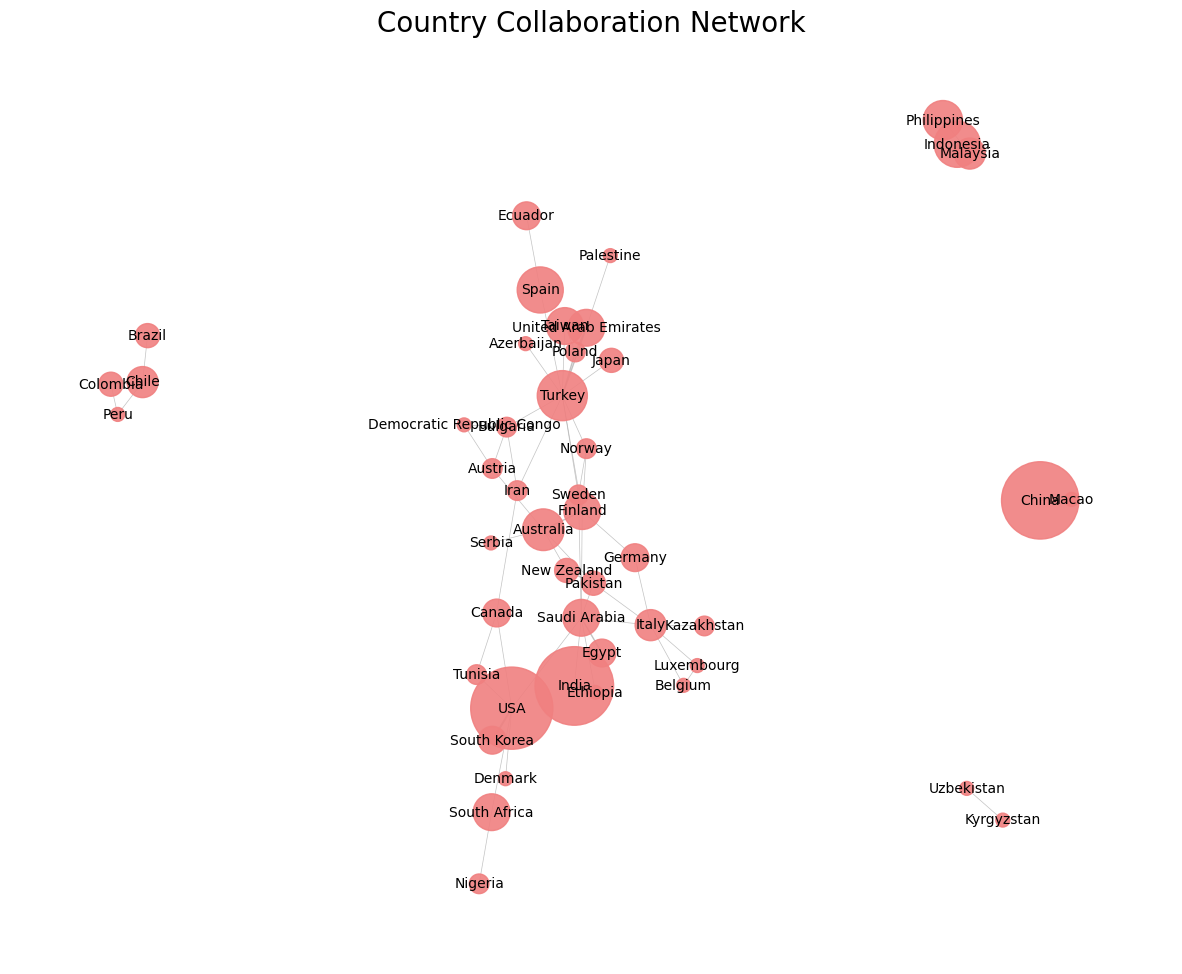

In [24]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
from collections import Counter, defaultdict
from itertools import combinations
import re

# --- Country Collaboration Network Analysis ---

# Drop rows where 'Affiliations' is NaN
affiliations_df_for_countries = df.dropna(subset=['Affiliations']).copy()

# Function to extract country from an affiliation string (similar to previous step)
def extract_country_from_affiliation(affiliation_str):
    parts = re.split(r'[,;]', affiliation_str)
    if parts:
        country = parts[-1].strip()
        country = re.sub(r'\([^)]*\)', '', country)
        country = re.sub(r'\d+', '', country)
        country = re.sub(r'[\W_]+', ' ', country)
        country = country.strip().title()

        if 'Usa' in country: country = 'USA'
        elif 'United States' in country: country = 'USA'
        elif 'Uk' in country: country = 'UK'
        elif 'United Kingdom' in country: country = 'UK'
        elif 'Peoples R China' in country or 'Pr China' in country: country = 'China'
        elif 'Germany Federal Republic' in country: country = 'Germany'
        elif 'Korea South' in country: country = 'South Korea'

        if country and len(country) > 2 and not country.isdigit():
            return country
    return None

country_collaborations = []
country_publication_counts = defaultdict(int)

for _, row in affiliations_df_for_countries.iterrows():
    # Get all affiliations for the current paper
    all_raw_affiliations = [aff.strip() for aff in row['Affiliations'].split(';') if aff.strip()]

    countries_in_paper = set()
    for aff in all_raw_affiliations:
        country = extract_country_from_affiliation(aff)
        if country:
            countries_in_paper.add(country)
            # Ensure country publication counts are only incremented once per country per paper
            # This is handled by adding to a set and then iterating unique countries

    # If there are multiple unique countries, they are collaborating
    if len(countries_in_paper) > 1:
        for c1, c2 in combinations(countries_in_paper, 2):
            country_collaborations.append(tuple(sorted((c1, c2))))

# Count the frequency of each country collaboration
country_collaboration_counts = Counter(country_collaborations)

# Update country_publication_counts based on unique countries in papers
# Re-initialize to count unique paper contributions properly
country_publication_counts = defaultdict(int)
for _, row in affiliations_df_for_countries.iterrows():
    all_raw_affiliations = [aff.strip() for aff in row['Affiliations'].split(';') if aff.strip()]
    countries_in_paper = set()
    for aff in all_raw_affiliations:
        country = extract_country_from_affiliation(aff)
        if country:
            countries_in_paper.add(country)
    for country in countries_in_paper:
        country_publication_counts[country] += 1

# Create a graph for country collaborations
G_countries = nx.Graph()

# Add nodes and edges to the graph
for (c1, c2), weight in country_collaboration_counts.items():
    G_countries.add_edge(c1, c2, weight=weight)

# Calculate node sizes based on the number of publications each country is involved in
node_sizes_countries = [country_publication_counts.get(node, 0) * 100 for node in G_countries.nodes()] # Scale for better visibility
edge_widths_countries = [G_countries[u][v]['weight'] * 0.5 for u, v in G_countries.edges()] # Scale for better visibility

# Draw the country collaboration network
plt.figure(figsize=(15, 12))
pos_countries = nx.spring_layout(G_countries, k=0.15, iterations=50)

nx.draw_networkx_nodes(G_countries, pos_countries, node_size=node_sizes_countries, node_color='lightcoral', alpha=0.9)
nx.draw_networkx_edges(G_countries, pos_countries, width=edge_widths_countries, edge_color='darkgray', alpha=0.7)
nx.draw_networkx_labels(G_countries, pos_countries, font_size=10, font_color='black')

plt.title('Country Collaboration Network', size=20)
plt.axis('off')
plt.show()

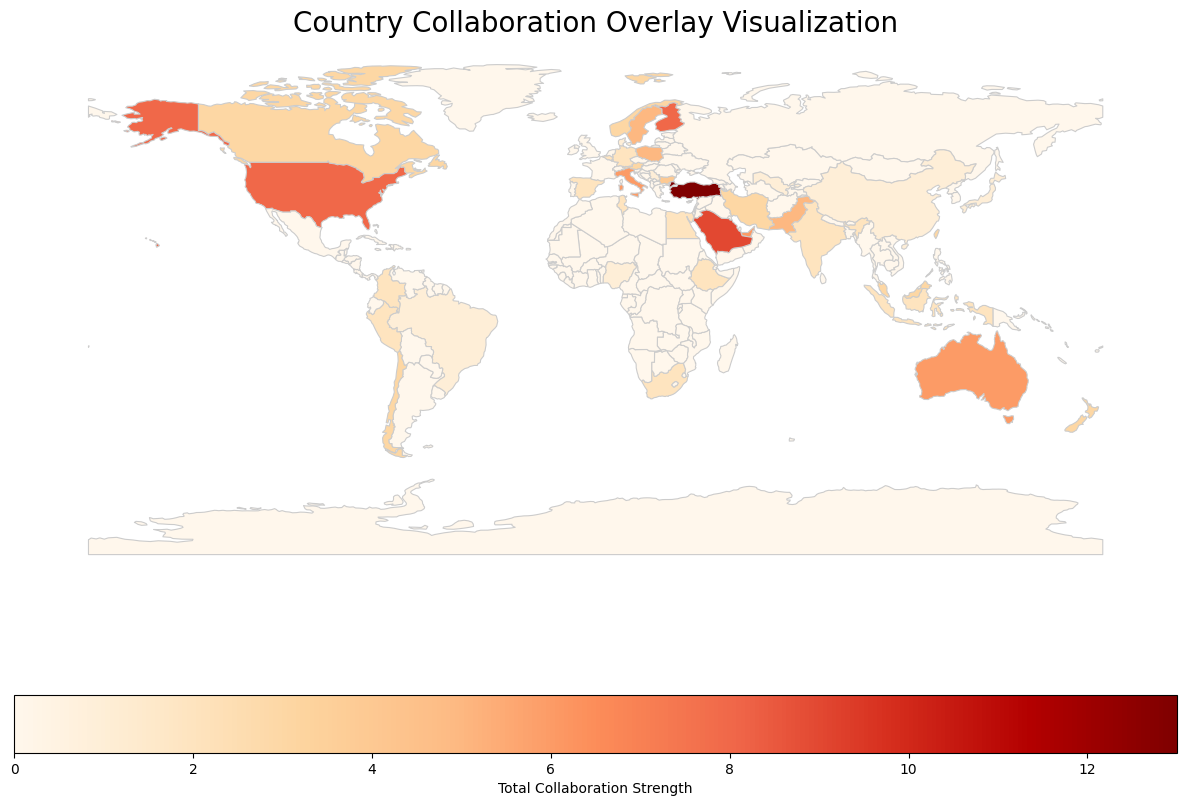

In [25]:
# Import necessary libraries
import geopandas
import matplotlib.pyplot as plt
import pandas as pd
from collections import Counter, defaultdict
from itertools import combinations
import re
import networkx as nx
import requests
import zipfile
import io
import os
from google.colab import files # Required for file upload if running interactively

# --- Code from cell_id: KDGYpZfmHnn (Load DataFrame) ---
# Assuming the file 'HealthCareSystem.csv' has already been uploaded
# and is accessible. If not, the 'files.upload()' step would be needed.
# For a self-contained execution, we'll ensure df is loaded.

# If df is not already defined in the current kernel session, load it.
# In a typical Colab environment, 'df' might persist, but for robustness,
# we ensure it's loaded if this cell is run independently.
try:
    df.head() # Try to access df to see if it exists
except NameError:
    print("DataFrame 'df' not found, attempting to load 'HealthCareSystem.csv'.")
    # This part assumes 'HealthCareSystem.csv' is available in the environment
    # If it's not, files.upload() would be needed for interactive use.
    # For automated execution, ensure the file is present.
    df = pd.read_csv("HealthCareSystem.csv")
    print("DataFrame 'df' loaded.")

# --- Code from cell_id: 5b0725bb (Download and Extract World Map) ---
download_url = "https://naturalearth.s3.amazonaws.com/110m_cultural/ne_110m_admin_0_countries.zip"
output_dir = "./ne_110m_admin_0_countries"
if not os.path.exists(output_dir):
    os.makedirs(output_dir)
headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36'}
response = requests.get(download_url, headers=headers)
response.raise_for_status()
with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    z.extractall(output_dir)
world_map_path = os.path.join(output_dir, "ne_110m_admin_0_countries.shp")

# --- Code from cell_id: 8045ea3b (Country Collaboration Network Analysis) ---
# Drop rows where 'Affiliations' is NaN
affiliations_df_for_countries = df.dropna(subset=['Affiliations']).copy()

# Function to extract country from an affiliation string (similar to previous step)
def extract_country_from_affiliation(affiliation_str):
    parts = re.split(r'[,;]', affiliation_str)
    if parts:
        country = parts[-1].strip()
        country = re.sub(r'\\([^)]*\\)', '', country)
        country = re.sub(r'\\d+', '', country)
        country = re.sub(r'[\\W_]+', ' ', country)
        country = country.strip().title()

        if 'Usa' in country: country = 'USA'
        elif 'United States' in country: country = 'USA'
        elif 'Uk' in country: country = 'UK'
        elif 'United Kingdom' in country: country = 'UK'
        elif 'Peoples R China' in country or 'Pr China' in country: country = 'China'
        elif 'Germany Federal Republic' in country: country = 'Germany'
        elif 'Korea South' in country: country = 'South Korea'

        if country and len(country) > 2 and not country.isdigit():
            return country
    return None

country_collaborations = []
country_publication_counts = defaultdict(int)

for _, row in affiliations_df_for_countries.iterrows():
    all_raw_affiliations = [aff.strip() for aff in row['Affiliations'].split(';') if aff.strip()]
    countries_in_paper = set()
    for aff in all_raw_affiliations:
        country = extract_country_from_affiliation(aff)
        if country:
            countries_in_paper.add(country)

    if len(countries_in_paper) > 1:
        for c1, c2 in combinations(countries_in_paper, 2):
            country_collaborations.append(tuple(sorted((c1, c2))))

country_collaboration_counts = Counter(country_collaborations)

country_publication_counts = defaultdict(int)
for _, row in affiliations_df_for_countries.iterrows():
    all_raw_affiliations = [aff.strip() for aff in row['Affiliations'].split(';') if aff.strip()]
    countries_in_paper = set()
    for aff in all_raw_affiliations:
        country = extract_country_from_affiliation(aff)
        if country:
            countries_in_paper.add(country)
    for country in countries_in_paper:
        country_publication_counts[country] += 1

G_countries = nx.Graph()
for (c1, c2), weight in country_collaboration_counts.items():
    G_countries.add_edge(c1, c2, weight=weight)

# --- Original Code for Country Overlay Visualization (cell_id: 587c57df) ---

world = geopandas.read_file(world_map_path)

total_collaborations_per_country = defaultdict(int)
for node in G_countries.nodes():
    total_collaborations_per_country[node] = sum(G_countries[node][neighbor]['weight'] for neighbor in G_countries.neighbors(node))

collaborations_df = pd.DataFrame(list(total_collaborations_per_country.items()), columns=['Country', 'Total Collaborations'])

country_name_mapping = {
    'USA': 'United States of America',
    'UK': 'United Kingdom',
    'China': 'China',
    'South Korea': 'Republic of Korea',
    'Iran': 'Iran',
    'Germany': 'Germany',
    'Canada': 'Canada',
    'France': 'France',
    'India': 'India',
    'Japan': 'Japan',
    'Australia': 'Australia',
    'Malaysia': 'Malaysia',
    'Belgium': 'Belgium',
    'Italy': 'Italy',
    'Turkey': 'Turkey',
    'Netherlands': 'Netherlands',
    'Portugal': 'Portugal',
    'Spain': 'Spain',
    'Brazil': 'Brazil',
    'Egypt': 'Egypt',
    'Taiwan': 'Taiwan',
    'Tunisia': 'Tunisia',
    'Indonesia': 'Indonesia',
    'Switzerland': 'Switzerland',
    'Poland': 'Poland',
    'Sweden': 'Sweden',
    'Pakistan': 'Pakistan',
    'Vietnam': 'Vietnam',
    'Singapore': 'Singapore',
    'Saudi Arabia': 'Saudi Arabia',
    'Greece': 'Greece',
    'Hong Kong': 'Hong Kong',
    'Ireland': 'Ireland',
    'Denmark': 'Denmark',
    'Austria': 'Austria',
    'Chile': 'Chile',
    'Colombia': 'Colombia',
    'Finland': 'Finland',
    'Hungary': 'Hungary',
    'Mexico': 'Mexico',
    'Nigeria': 'Nigeria',
    'New Zealand': 'New Zealand',
    'Norway': 'Norway',
    'Romania': 'Romania',
    'Russia': 'Russia',
    'Slovakia': 'Slovakia',
    'South Africa': 'South Africa',
    'Ukraine': 'Ukraine',
    'Argentina': 'Argentina',
    'Bulgaria': 'Bulgaria',
    'Czech Republic': 'Czech Republic',
    'Croatia': 'Croatia',
    'Ethiopia': 'Ethiopia',
    'Jordan': 'Jordan',
    'Peru': 'Peru',
    'Qatar': 'Qatar',
    'Serbia': 'Serbia',
    'Slovenia': 'Slovenia',
    'Thailand': 'Thailand',
    'United Arab Emirates': 'United Arab Emirates',
    'Uzbekistan': 'Uzbekistan'
}

collaborations_df['Country_Geo'] = collaborations_df['Country'].map(country_name_mapping)

world_with_collaborations = world.merge(collaborations_df, left_on='NAME', right_on='Country_Geo', how='left')

world_with_collaborations['Total Collaborations'] = world_with_collaborations['Total Collaborations'].fillna(0)

fig, ax = plt.subplots(1, 1, figsize=(15, 10))
world_with_collaborations.plot(column='Total Collaborations', cmap='OrRd', linewidth=0.8, ax=ax, edgecolor='0.8', legend=True,
                               legend_kwds={'label': "Total Collaboration Strength",
                                            'orientation': "horizontal"})
ax.set_title('Country Collaboration Overlay Visualization', size=20)
ax.set_axis_off()
plt.show()

First, let's explore the distribution of `Index Keywords` to identify the prominent research areas. We'll extract all individual keywords, count their occurrences, and visualize the top ones.

/tmp/ipykernel_469/612471445.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Frequency', y='Keyword', data=top_keywords_df, palette='viridis')


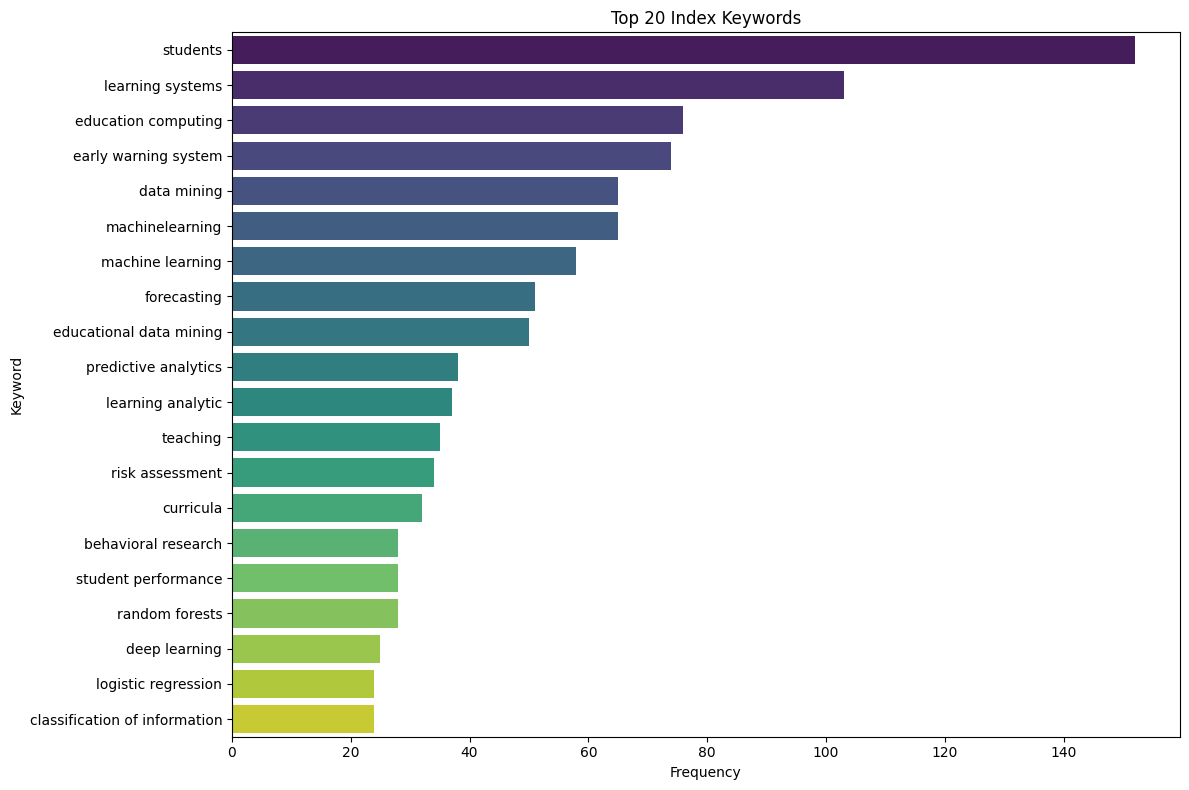

In [26]:
from collections import Counter
import re
import matplotlib.pyplot as plt
import seaborn as sns

# Drop rows where 'Index Keywords' is NaN to avoid errors during splitting
keywords_df = df.dropna(subset=['Index Keywords']).copy()

# Split keywords and clean them (remove leading/trailing spaces, lowercase)
all_keywords = []
for index_keywords_str in keywords_df['Index Keywords']:
    # Split by semicolon and handle potential issues like extra spaces
    keywords = [re.sub(r'[^a-zA-Z0-9 ]', '', k.strip().lower()) for k in index_keywords_str.split(';') if k.strip()]
    all_keywords.extend(keywords)

# Count the frequency of each keyword
keyword_counts = Counter(all_keywords)

# Get the top N keywords
num_top_keywords = 20
top_keywords = keyword_counts.most_common(num_top_keywords)

# Convert to DataFrame for easier plotting
top_keywords_df = pd.DataFrame(top_keywords, columns=['Keyword', 'Frequency'])

# Plotting the top keywords
plt.figure(figsize=(12, 8))
sns.barplot(x='Frequency', y='Keyword', data=top_keywords_df, palette='viridis')
plt.title(f'Top {num_top_keywords} Index Keywords')
plt.xlabel('Frequency')
plt.ylabel('Keyword')
plt.tight_layout()
plt.show()

Now that we have identified the top keywords, let's visualize their trends over time (by year). This will show how the focus on these research areas has evolved.

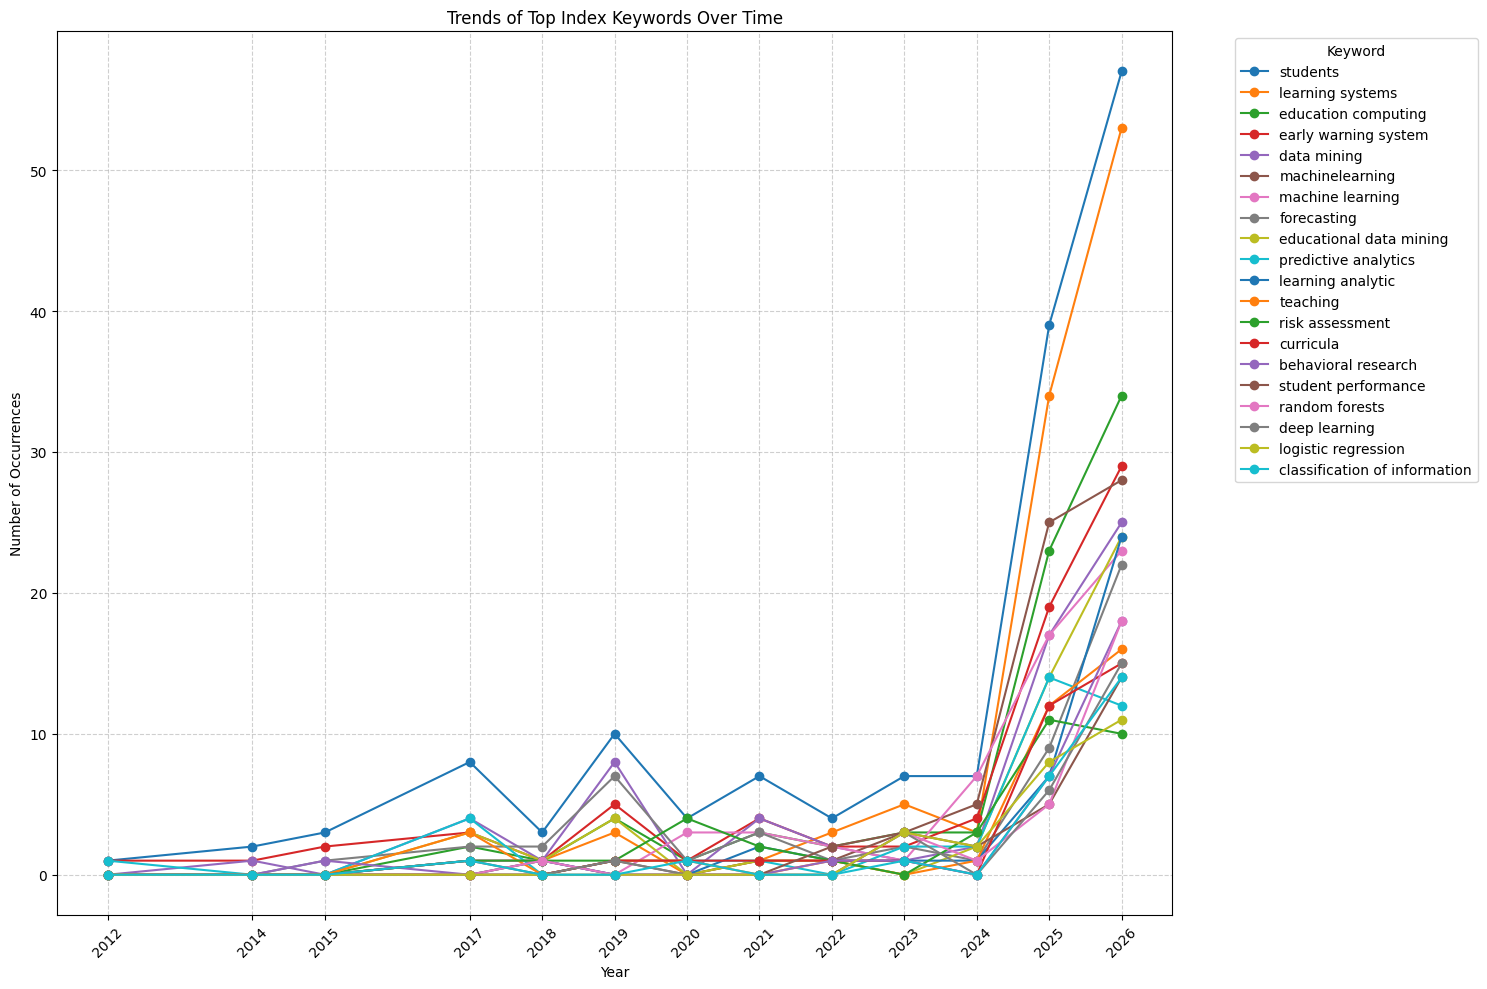

In [27]:
# Prepare data for trend analysis of top keywords
# Create a dictionary to store yearly counts for each top keyword
keyword_yearly_trends = {keyword: [] for keyword, _ in top_keywords}
years = sorted(keywords_df['Year'].unique())

for year in years:
    # Filter dataframe for the current year
    df_year = keywords_df[keywords_df['Year'] == year]

    # Get all keywords for the current year
    yearly_keywords = []
    for index_keywords_str in df_year['Index Keywords']:
        keywords = [re.sub(r'[^a-zA-Z0-9 ]', '', k.strip().lower()) for k in index_keywords_str.split(';') if k.strip()]
        yearly_keywords.extend(keywords)

    # Count occurrences of top keywords in the current year
    yearly_counts = Counter(yearly_keywords)

    for keyword, _ in top_keywords:
        keyword_yearly_trends[keyword].append(yearly_counts[keyword])

# Convert to DataFrame for plotting
trends_df = pd.DataFrame(keyword_yearly_trends, index=years)
trends_df.index.name = 'Year'
trends_df = trends_df.reset_index()

# Plotting the trends
plt.figure(figsize=(15, 10))

for keyword in trends_df.columns[1:]: # Skip the 'Year' column
    plt.plot(trends_df['Year'], trends_df[keyword], label=keyword, marker='o', linestyle='-')

plt.title('Trends of Top Index Keywords Over Time')
plt.xlabel('Year')
plt.ylabel('Number of Occurrences')
plt.legend(title='Keyword', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(years, rotation=45)
plt.tight_layout()
plt.show()

Let's examine the distribution of `Document Type` to see what kind of publications are most common in this dataset.

/tmp/ipykernel_469/954404132.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Count', y='Document Type', data=document_type_counts, palette='mako')


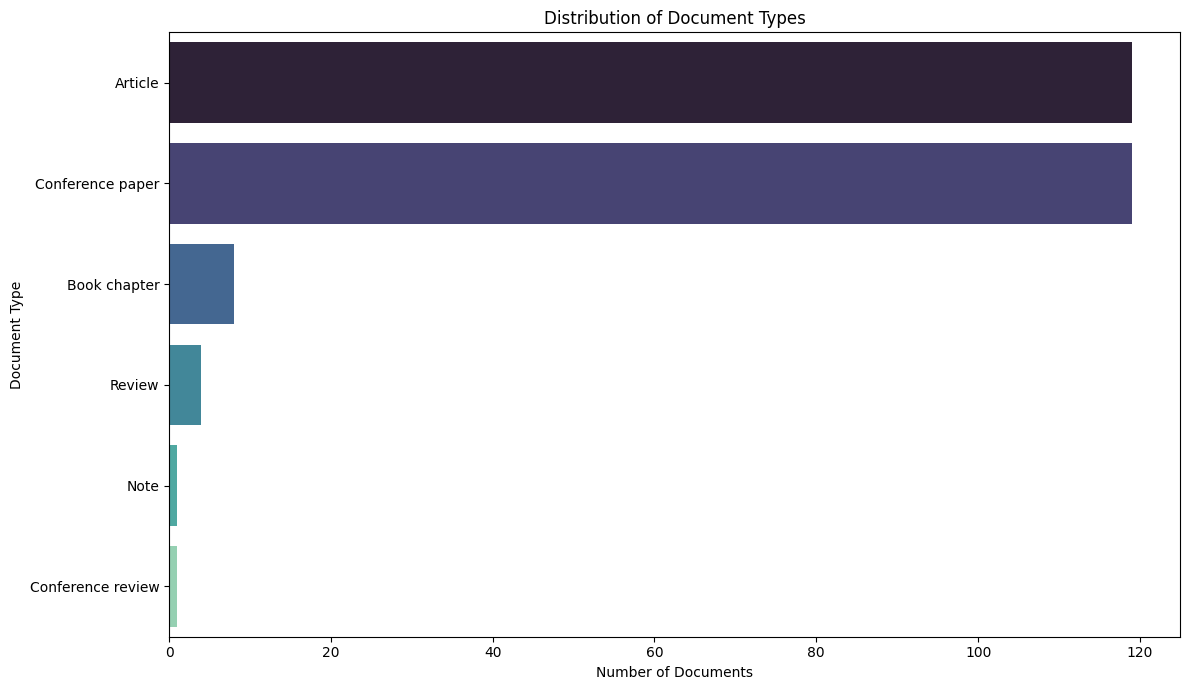

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count the occurrences of each document type
document_type_counts = df['Document Type'].value_counts().reset_index()
document_type_counts.columns = ['Document Type', 'Count']

# Plotting the distribution of document types
plt.figure(figsize=(12, 7))
sns.barplot(x='Count', y='Document Type', data=document_type_counts, palette='mako')
plt.title('Distribution of Document Types')
plt.xlabel('Number of Documents')
plt.ylabel('Document Type')
plt.tight_layout()
plt.show()

Let's visualize the **Top 10 Most Prevalent Application Areas** based on the `Index Keywords` to understand the primary focus of research within this dataset.

/tmp/ipykernel_469/3904862021.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Frequency', y='Keyword', data=top_10_keywords_df, palette='magma')


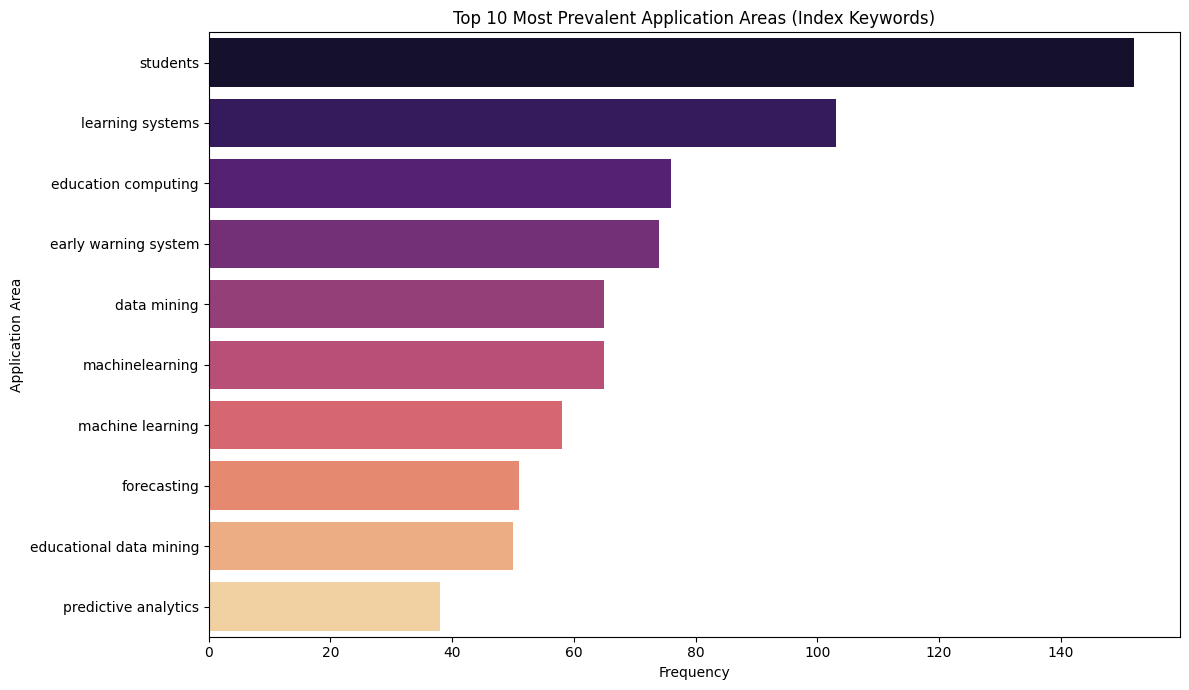

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure top_keywords_df is available from previous steps
# If not, the previous code to generate it should be re-run or this cell should be combined.
# Assuming top_keywords_df is already in the kernel state.

# Get the top 10 keywords for this visualization
top_10_keywords_df = top_keywords_df.head(10)

# Plotting the top 10 application areas
plt.figure(figsize=(12, 7))
sns.barplot(x='Frequency', y='Keyword', data=top_10_keywords_df, palette='magma')
plt.title('Top 10 Most Prevalent Application Areas (Index Keywords)')
plt.xlabel('Frequency')
plt.ylabel('Application Area')
plt.tight_layout()
plt.show()

Let's identify and visualize the **Top 20 Authors by Total Publications** to highlight the most prolific contributors in this dataset.

/tmp/ipykernel_469/3107768042.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Publication Count', y='Author', data=top_authors_df, palette='rocket')


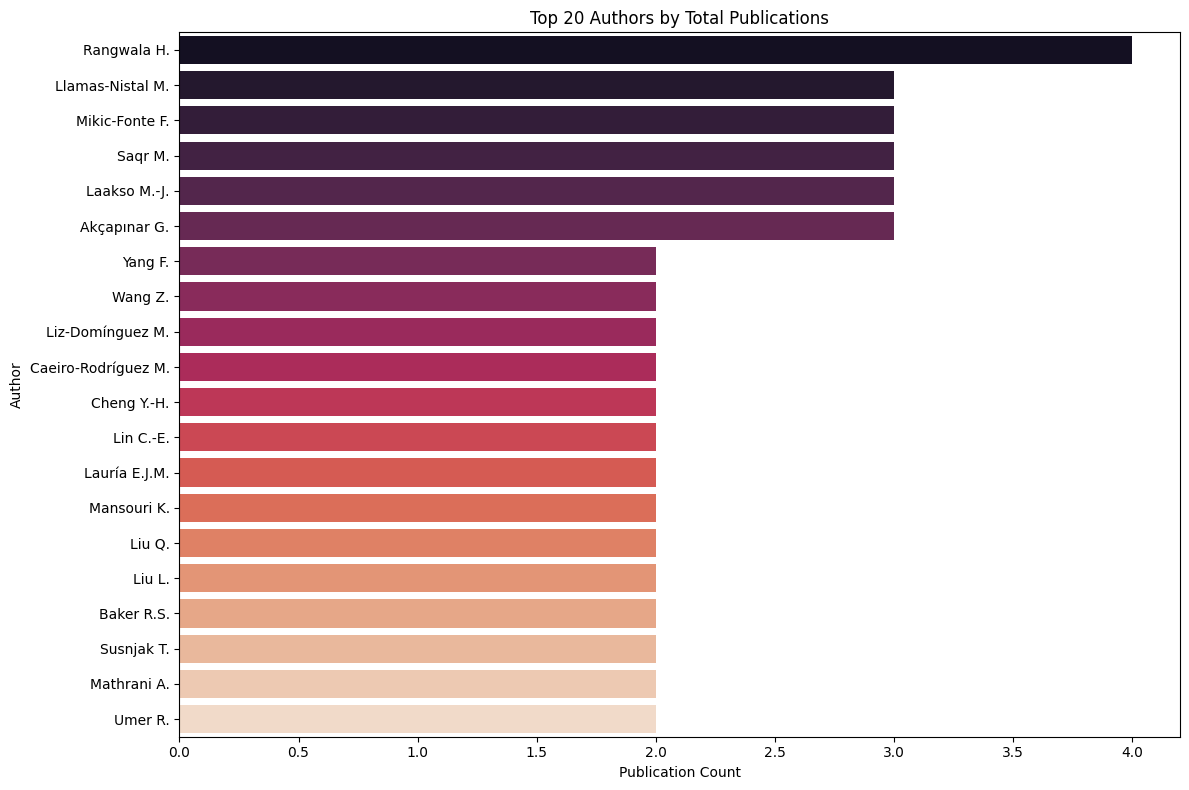

In [30]:
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns

# Drop rows where 'Authors' is NaN
authors_df = df.dropna(subset=['Authors']).copy()

# Split authors and clean them (remove leading/trailing spaces, lowercase)
all_authors = []
for authors_str in authors_df['Authors']:
    # Split by semicolon and handle potential issues like extra spaces
    authors = [author.strip() for author in authors_str.split(';') if author.strip()]
    all_authors.extend(authors)

# Count the frequency of each author
author_counts = Counter(all_authors)

# Get the top 20 authors
num_top_authors = 20
top_authors = author_counts.most_common(num_top_authors)

# Convert to DataFrame for easier plotting
top_authors_df = pd.DataFrame(top_authors, columns=['Author', 'Publication Count'])

# Plotting the top authors
plt.figure(figsize=(12, 8))
sns.barplot(x='Publication Count', y='Author', data=top_authors_df, palette='rocket')
plt.title(f'Top {num_top_authors} Authors by Total Publications')
plt.xlabel('Publication Count')
plt.ylabel('Author')
plt.tight_layout()
plt.show()